In [99]:
from pathlib import Path
import io
import hashlib
import json
import h5py
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D

In [4]:
cwd = Path.cwd().resolve()
CODE_ROOT = next(
    p for p in (cwd, *cwd.parents) if (p / "src").is_dir() and (p / ".git").exists()
)
CATALOG_ROOT = CODE_ROOT / "data/galaxy_absorption/catalogs"
SNAPNUM = 90
catalog_path = CATALOG_ROOT / "EX_0" / f"groups_{SNAPNUM:03d}.hdf5"

print("Code root:", CODE_ROOT)
print("Catalog:", catalog_path)
print("SHA256:", hashlib.sha256(catalog_path.read_bytes()).hexdigest())

Code root: /Users/antareepgogoi/Codes/lya_forest_ml_galaxies
Catalog: /Users/antareepgogoi/Codes/lya_forest_ml_galaxies/data/galaxy_absorption/catalogs/EX_0/groups_090.hdf5
SHA256: 42830da8abd26d317848bd0323833c633116216c3cc9078e765b0cf7a6a97960


In [6]:
with h5py.File(catalog_path, "r") as f:
    header = dict(f["Header"].attrs)
    print("\nCatalog header:", header)

    field = {
        "Group": [
            "GroupPos", "GroupVel", "GroupFirstSub", "GroupLenType", "Group_M_Crit200", "Group_R_Crit200", "Group_M_TopHat200", "Group_R_TopHat200",
        ],
        "Subhalo": [
            "SubhaloPos", "SubhaloVel", "SubhaloGrNr", "SubhaloMassType", "SubhaloLenType", "SubhaloSFR", "SubhaloIDMostbound",
        ],
    }
    for group, names in field.items():
        print(f"\n{group} fields:", {
            name: f[group][name].shape if name in f[group] else "MISSING" for name in names
        })

    h = float(header["HubbleParam"])
    m200 = f["Group/Group_M_Crit200"][:].astype(float) * 1e10 / h
    r200 = f["Group/Group_R_Crit200"][:]
    rvir = f["Group/Group_R_TopHat200"][:]

    print("\nHalo counts before galaxy/resolution cuts:")
    for logm in (10.5, 11.0, 11.5, 12.0, 12.5, 13.0):
        count = np.count_nonzero(m200 >= 10**logm)
        print(f"M200c >= 10^{logm:g} Msun: {count}")

    valid = np.isfinite(rvir) & np.isfinite(r200) & (rvir > 0) & (r200 > 0)
    print("\nRvir/R200c percentiles [5, 50, 95]:", np.percentile(rvir[valid] / r200[valid], [5, 50, 95]))


Catalog header: {'BoxSize': 25000.0, 'FlagDoubleprecision': 0, 'Git_commit': b'4ab97a2c5659df3e83e01c53f8142816fc0db675', 'Git_date': b'Tue May 3 10:27:55 2016 +0200', 'HubbleParam': 0.6711, 'Ngroups_ThisFile': 19994, 'Ngroups_Total': 19994, 'Nids_ThisFile': 13151431, 'Nids_Total': 13151431, 'Nsubgroups_ThisFile': 17124, 'Nsubgroups_Total': 17124, 'NumFiles': 1, 'Omega0': 0.3, 'OmegaLambda': 0.7, 'Redshift': 2.220446049250313e-16, 'Time': 0.9999999999999998}

Group fields: {'GroupPos': (19994, 3), 'GroupVel': (19994, 3), 'GroupFirstSub': (19994,), 'GroupLenType': (19994, 6), 'Group_M_Crit200': (19994,), 'Group_R_Crit200': (19994,), 'Group_M_TopHat200': (19994,), 'Group_R_TopHat200': (19994,)}

Subhalo fields: {'SubhaloPos': (17124, 3), 'SubhaloVel': (17124, 3), 'SubhaloGrNr': (17124,), 'SubhaloMassType': (17124, 6), 'SubhaloLenType': (17124, 6), 'SubhaloSFR': (17124,), 'SubhaloIDMostbound': (17124,)}

Halo counts before galaxy/resolution cuts:
M200c >= 10^10.5 Msun: 1401
M200c >= 10^1

In [17]:
with h5py.File(catalog_path, "r") as f:
    g, s = f["Group"], f["Subhalo"]
    h = float(f["Header"].attrs["HubbleParam"])

    first = g["GroupFirstSub"][:].astype(np.int64)
    group_id = np.flatnonzero((first >= 0) & (first < len(s["SubhaloMassType"])))
    subhalo_id = first[group_id]

    assert np.array_equal(s["SubhaloGrNr"][:][subhalo_id], group_id)

    ex0 = pd.DataFrame({
        "group_id": group_id,
        "subhalo_id": subhalo_id,
        "M200c_Msun": g["Group_M_Crit200"][:][group_id].astype(float) * 1e10 / h,
        "Mstar_Msun": s["SubhaloMassType"][:, 4][subhalo_id].astype(float) * 1e10 / h,
        "SFR_Msun_yr": s["SubhaloSFR"][:][subhalo_id],
        "Rvir_ckpch": g["Group_R_TopHat200"][:][group_id],
        "R200c_ckpch": g["Group_R_Crit200"][:][group_id],
        "Ndm_fof": g["GroupLenType"][:, 1][group_id],
    })
    pos = s["SubhaloPos"][:][subhalo_id]

In [19]:
for j, axis in enumerate("xyz"):
    ex0[f"{axis}_ckpch"] = pos[:, j]

ex0 = ex0.loc[
    np.isfinite(ex0).all(axis=1)
    & (ex0["M200c_Msun"] >= 1e11)
    & (ex0["Mstar_Msun"] >= 1e9)
    & (ex0["SFR_Msun_yr"] >= 0)
    & (ex0["Rvir_ckpch"] > 0)
    & (ex0["R200c_ckpch"] > 0)
].copy()

ex0["sSFR_yr_inv"] = ex0["SFR_Msun_yr"] / ex0["Mstar_Msun"]
ex0["type_EX0"] = np.where(ex0["sSFR_yr_inv"] >= 1e-11, "star-forming", "low_sSFR")
ex0["mass_bin"] = pd.cut(
    np.log10(ex0["M200c_Msun"]),
    bins=[11.0, 11.5, 12.0, 12.5, np.inf],
    labels=["11-11.5", "11.5-12", "12-12.5", ">=12.5"],
    right=False,
)

In [20]:
ex0 = ex0.sample(frac=1, random_state=42)
ex0["_round"] = ex0.groupby(["mass_bin", "type_EX0"], observed=True).cumcount()
ex0 = ex0.sort_values("_round", kind="stable").drop(columns="_round").reset_index(drop=True)
ex0.insert(0, "priority", np.arange(1, len(ex0) + 1))
ex0["pilot"] = ex0["priority"] <= 20

In [26]:
OUT_ROOT = CODE_ROOT / "outputs/galaxy_absorption"
OUT_ROOT.mkdir(parents=True, exist_ok=True)
ex0.to_csv(OUT_ROOT / "ex0_sample_z0.csv", index=False)

print(f"Selected EX0 central galaxies: {len(ex0)}")
print("\nFull sample; rows are log10(M200c/Msun):")
print(pd.crosstab(ex0["mass_bin"], ex0["type_EX0"]).to_string())

Selected EX0 central galaxies: 256

Full sample; rows are log10(M200c/Msun):
type_EX0  low_sSFR  star-forming
mass_bin                        
11-11.5          2            65
11.5-12          5            99
12-12.5         35            31
>=12.5          18             1


In [22]:
pilot = ex0.loc[ex0["pilot"]]
print(f"\nFirst {len(pilot)} halos:")
print(pd.crosstab(pilot["mass_bin"], pilot["type_EX0"]).to_string())

print("\nFOF DM-particle counts [minimum, median, maximum]")
print(ex0["Ndm_fof"].quantile([0, 0.5, 1]).round().astype(int).to_list())
print("\nSaved:", OUT_ROOT / "ex0_sample_z0.csv")


First 20 halos:
type_EX0  low_sSFR  star-forming
mass_bin                        
11-11.5          2             3
11.5-12          2             3
12-12.5          3             3
>=12.5           3             1

FOF DM-particle counts [minimum, median, maximum]
[1265, 6043, 1158614]

Saved: /Users/antareepgogoi/Codes/lya_forest_ml_galaxies/data/galaxy_absorption/ex0_sample_z0.csv


In [49]:
models = ["EX_0", "EX_1", "EX_2", "EX_3"]
seed = 42
b_edges = np.array([0, 0.25, 0.5, 0.75, 1.0])
rays_per_bin_axis = 4
rays_per_halo = 3 * (len(b_edges) - 1) * rays_per_bin_axis

ex0 = pd.read_csv(OUT_ROOT / "ex0_sample_z0.csv")
matches = pd.read_csv(OUT_ROOT / "galaxy_matches_090.csv")
match_info = json.loads((OUT_ROOT / "galaxy_matches_090.json").read_text())

common_ids = match_info["common_group_ids_EX0"]
halos = ex0.loc[ex0["group_id"].isin(common_ids)].copy()
halos = halos.sort_values("priority")
match_lookup = matches.set_index(["group_id", "model"])

catalogs = {}
for model in models:
    path = CATALOG_ROOT / model / f"groups_{SNAPNUM:03d}.hdf5"
    digest = hashlib.sha256(path.read_bytes()).hexdigest()
    assert digest == match_info["catalog_sha256"][model], f"Catalog SHA256 mismatch for {model}"

    with h5py.File(path, "r") as f:
        catalogs[model] = {
            "position": f["Subhalo/SubhaloPos"][:],
            "velocity": f["Subhalo/SubhaloVel"][:],
            "rvir": f["Group/Group_R_TopHat200"][:],
        }
        if model == "EX_0":
            box = float(f["Header"].attrs["BoxSize"])
            a = float(f["Header"].attrs["Time"])
            h = float(f["Header"].attrs["HubbleParam"])

rows = []

for halo in halos.itertuples(index=False):
    group0 = int(halo.group_id)
    rng = np.random.default_rng([seed, group0])
    radius0 = float(halo.Rvir_ckpch)

    counterparts = {}
    for model in models:
        if model == "EX_0":
            group, subhalo = group0, int(halo.subhalo_id)
        else:
            match = match_lookup.loc[(group0, model)]
            group, subhalo = int(match["matched_group_id"]), int(match["matched_subhalo_id"])

        cat = catalogs[model]
        counterparts[model] = (
            group, subhalo, cat["position"][subhalo], cat["velocity"][subhalo], cat["rvir"][group]
        )

    local_ray = 0
    for axis in (1, 2, 3):
        los_axis = axis - 1
        transverse = [j for j in range(3) if j != los_axis]

        for b_bin, (lower, upper) in enumerate(zip(b_edges[:-1], b_edges[1:])):
            area_weight = (upper**2 - lower**2) / (3 * rays_per_bin_axis)

            for draw in range(rays_per_bin_axis):
                b_scaled = np.sqrt(rng.uniform(lower**2, upper**2))
                phi = rng.uniform(0, 2 * np.pi)
                b = radius0 * b_scaled

                offset = np.zeros(3)
                offset[transverse] = b * np.array([np.cos(phi), np.sin(phi)])
                ray_id = group0 * rays_per_halo + local_ray

                for model in models:
                    group, subhalo, center, velocity, radius = counterparts[model]
                    cofm =  (center + offset) % box

                    rows.append({
                        "snapnum": SNAPNUM,
                        "model": model,
                        "ray_id": ray_id,
                        "priority": int(halo.priority),
                        "pilot": bool(halo.pilot),
                        "group_id_EX0": group0,
                        "group_id_model": group,
                        "subhalo_id_model": subhalo,
                        "axis": axis,
                        "b_bin": b_bin,
                        "b_over_Rvir_EX0": b_scaled,
                        "b_over_Rvir_model": b / radius if radius > 0 else np.nan,
                        "b_ckpch": b,
                        "phi_rad": phi,
                        "area_weight": area_weight,
                        "cofm_x_ckpch": cofm[0],
                        "cofm_y_ckpch": cofm[1],
                        "cofm_z_ckpch": cofm[2],
                        "galaxy_los_ckpch": center[los_axis],
                        "galaxy_vlos_kms": velocity[los_axis],
                        "mass_bin": halo.mass_bin,
                        "type_EX0": halo.type_EX0,
                        "M200c_EX0_Msun": float(halo.M200c_Msun),
                        "Rvir_EX0_ckpch": radius0,
                    })
                local_ray += 1

In [50]:

rays = pd.DataFrame(rows)
pilot_rays = rays.loc[rays["pilot"]].copy()

assert not rays.duplicated(["model", "ray_id"]).any(), "Duplicate rays found"

rays.to_csv(OUT_ROOT / "galaxy_rays_090.csv", index=False)
pilot_rays.to_csv(OUT_ROOT / "galaxy_rays_pilot_090.csv", index=False)

geometry = {
    "snapnum": SNAPNUM,
    "models": models,
    "seed": seed,
    "seed_inputs": ["seed", "EX0_group_id"],
    "numpy_version": np.__version__,
    "geometry": "Identical transverse offsets about each matched central subhalo",
    "reference_radius": "EX0 Group_R_TopHat200",
    "position_unit": "ckpc/h",
    "BoxSize_ckpch": box,
    "scale_factor": a,
    "HubbleParam": h,
    "axes": {"1": "x", "2": "y", "3": "z"},
    "b_over_Rvir_EX0_edges": b_edges.tolist(),
    "sampling": "Uniform projected area within each annulus",
    "annulus_area_fractions": np.diff(b_edges**2).tolist(),
    "rays_per_bin_axis": rays_per_bin_axis,
    "rays_per_halo_per_model": rays_per_halo,
    "line_of_sight": "Full periodic box",
    "n_halos": len(halos),
    "n_pilot_halos": int(halos["pilot"].sum()),
    "catalog_sha256": match_info["catalog_sha256"],
}
(OUT_ROOT / "galaxy_rays_090.json").write_text(
    json.dumps(geometry, indent=2) + "\n"
)
print("Matched halos:", len(halos))
print("Pilot halos:", int(halos["pilot"].sum()))
print("Full rays per model:")
print(rays.groupby("model").size())
print("Pilot rays per model:")
print(pilot_rays.groupby("model").size())

print("\nMatched sample by EX0 mass and type:")
display(pd.crosstab(halos["mass_bin"], halos["type_EX0"]))

print("\nPilot matches with center shifts greater than EX0 Rvir:")
large_shift = (
    matches["pilot"]
    & (matches["status"] == "accepted")
    & (matches["center_sep_Rvir_EX0"] > 1)
)
display(matches.loc[large_shift, [
    "group_id", "model", "fraction_EX0", "fraction_model",
    "center_sep_Rvir_EX0",
]])

Matched halos: 247
Pilot halos: 20
Full rays per model:
model
EX_0    11856
EX_1    11856
EX_2    11856
EX_3    11856
dtype: int64
Pilot rays per model:
model
EX_0    960
EX_1    960
EX_2    960
EX_3    960
dtype: int64

Matched sample by EX0 mass and type:


type_EX0,low_sSFR,star-forming
mass_bin,,
11-11.5,2,63
11.5-12,4,95
12-12.5,35,29
>=12.5,18,1



Pilot matches with center shifts greater than EX0 Rvir:


,group_id,model,fraction_EX0,fraction_model,center_sep_Rvir_EX0
266,30,EX_2,0.919957,0.928389,1.823000
270,517,EX_2,0.915415,0.911094,1.065493
513,6,EX_3,0.509167,0.803214,1.061642
517,369,EX_3,0.955476,0.880660,1.202480
520,218,EX_3,0.928571,0.934478,1.265841
522,30,EX_3,0.913266,0.911356,1.852632


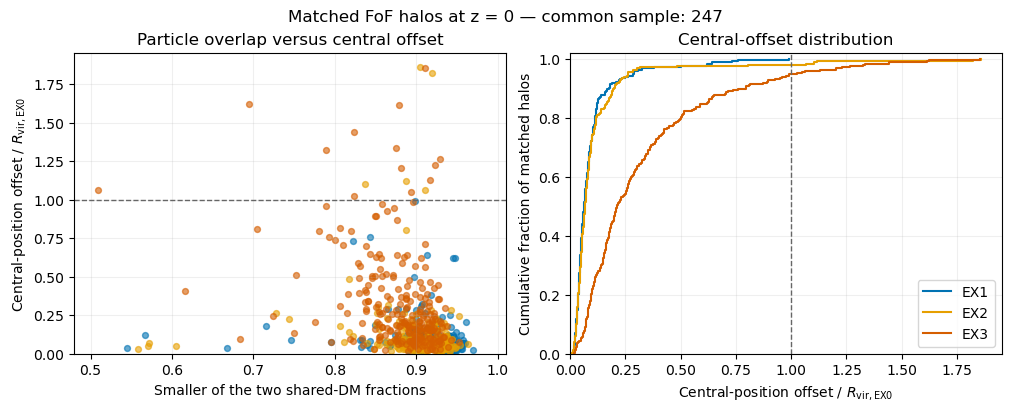

,n_halos,median_minimum_overlap,median_offset_Rvir,p95_offset_Rvir,n_offset_above_Rvir
model,,,,,
EX_1,247,0.927,0.061,0.287,0
EX_2,247,0.913,0.068,0.262,5
EX_3,247,0.890,0.210,1.013,13


In [51]:
FIG_ROOT = OUT_ROOT / "figures"
FIG_ROOT.mkdir(parents=True, exist_ok=True)

matches = pd.read_csv(OUT_ROOT / "galaxy_matches_090.csv")
match_info = json.loads(
    (OUT_ROOT / "galaxy_matches_090.json").read_text()
)

# Compare the same 247 EX0-selected halos in every model.
common_ids = match_info["common_group_ids_EX0"]
in_common_sample = matches["group_id"].isin(common_ids)
accepted = matches["status"].eq("accepted")
paired = matches.loc[in_common_sample & accepted].copy()

# A match must contain a substantial fraction of BOTH halos.
overlap_columns = ["fraction_EX0", "fraction_model"]
paired["minimum_overlap"] = paired[overlap_columns].min(axis=1)

colors = {
    "EX_1": "#0072B2",
    "EX_2": "#E69F00",
    "EX_3": "#D55E00",
}

fig, axes = plt.subplots(
    1, 2, figsize=(10, 4), constrained_layout=True
)
summary_rows = []

for model, color in colors.items():
    sample = paired.loc[paired["model"].eq(model)]
    overlap = sample["minimum_overlap"].to_numpy()
    offsets = sample["center_sep_Rvir_EX0"].to_numpy()
    label = model.replace("_", "")

    axes[0].scatter(
        overlap, offsets,
        s=18, alpha=0.6, color=color, label=label,
    )

    sorted_offsets = np.sort(offsets)
    cumulative_fraction = np.arange(1, len(offsets) + 1) / len(offsets)
    axes[1].step(
        sorted_offsets, cumulative_fraction,
        where="post", color=color, label=label,
    )

    summary_rows.append({
        "model": model,
        "n_halos": len(sample),
        "median_minimum_overlap": np.median(overlap),
        "median_offset_Rvir": np.median(offsets),
        "p95_offset_Rvir": np.percentile(offsets, 95),
        "n_offset_above_Rvir": int(np.count_nonzero(offsets > 1)),
    })

axes[0].axhline(1, color="0.4", linestyle="--", linewidth=1)
axes[0].set(
    xlabel="Smaller of the two shared-DM fractions",
    ylabel=r"Central-position offset / $R_{\rm vir,EX0}$",
    title="Particle overlap versus central offset",
    xlim=(0.48, 1.01),
    ylim=(0, None),
)

axes[1].axvline(1, color="0.4", linestyle="--", linewidth=1)
axes[1].set(
    xlabel=r"Central-position offset / $R_{\rm vir,EX0}$",
    ylabel="Cumulative fraction of matched halos",
    title="Central-offset distribution",
    xlim=(0, None),
    ylim=(0, 1.02),
)
axes[1].legend(loc="lower right")

for ax in axes:
    ax.grid(alpha=0.2)

fig.suptitle(f"Matched FoF halos at z = 0 — common sample: {len(common_ids)}")

figure_path = FIG_ROOT / "halo_matching_z0"
fig.savefig(figure_path.with_suffix(".pdf"), bbox_inches="tight")
fig.savefig(figure_path.with_suffix(".png"), dpi=200, bbox_inches="tight")
plt.show()

summary = pd.DataFrame(summary_rows).set_index("model")
summary.to_csv(OUT_ROOT / "halo_matching_summary_z0.csv")
display(summary.round(3))

In [52]:
import sys

ROOT = Path.cwd().resolve()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
from src.galaxy_measurements import rest_ew

# Synthetic example: uniform 20% absorption.
edges = np.linspace(0, 2500, 363)
flux = np.full(362, 0.8)

for center in (1250, 3):
    ew = rest_ew(flux, edges, galaxy_velocity=center, half_window=300)
    print(f"Center = {center:4d} km/s: EW = {ew:.6f} Å")

Center = 1250 km/s: EW = 0.486605 Å
Center =    3 km/s: EW = 0.486605 Å


In [ ]:
SPEC_ROOT = CODE_ROOT / "data/galaxy_absorption/spectra"
pilot = {}
loaded = []

for model in models:
    path = SPEC_ROOT / f"galaxy_pilot_{model}_090.hdf5"

    with h5py.File(path, "r") as handle:
        tau = handle["tau/H/1/1215"][:]
        metadata = handle["galaxy_metadata"]
        manifest_text = metadata["manifest_csv"].asstr()[()]
        rays = pd.read_csv(io.StringIO(manifest_text))

        assert len(rays) == len(tau)
        assert np.array_equal(rays["ray_id"], metadata["ray_id"][:])

        vmax = float(metadata.attrs["vmax_kms"])
        velfac = float(metadata.attrs["velfac_kms_per_ckpch"])

    # Preserve the connection between each manifest row and its spectrum.
    rays["spectrum_row"] = np.arange(len(rays))
    rays["galaxy_velocity_kms"] = (
        velfac * rays["galaxy_los_ckpch"] + rays["galaxy_vlos_kms"]
    ) % vmax
    rays = rays.set_index("ray_id")

    edges = np.linspace(0, vmax, tau.shape[1] + 1)
    pilot[model] = {
        "rays": rays,
        "flux": np.exp(-tau),
        "edges": edges,
        "vmax": vmax,
    }

    loaded.append({
        "model": model,
        "n_rays": tau.shape[0],
        "n_pixels": tau.shape[1],
        "dv_kms": vmax / tau.shape[1],
    })

display(pd.DataFrame(loaded).set_index("model"))

,n_rays,n_pixels,dv_kms
model,,,
EX_0,960,2499,1.0004
EX_1,960,2499,1.0004
EX_2,960,2499,1.0004
EX_3,960,2499,1.0004


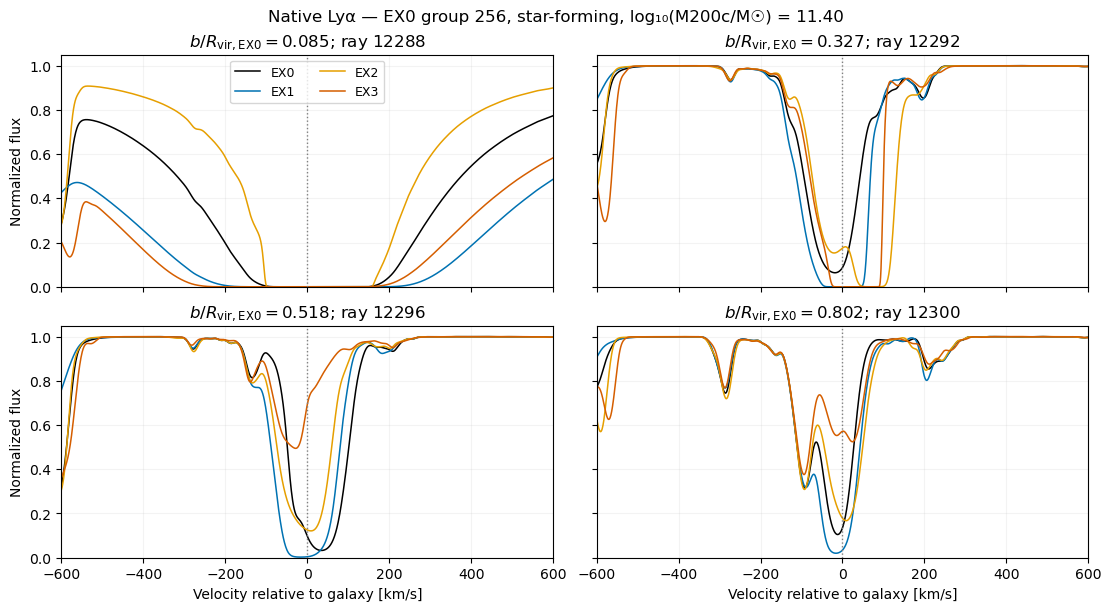

In [55]:
reference = pilot["EX_0"]["rays"]
first = reference.sort_values("priority", kind="stable").iloc[0]
group0 = int(first["group_id_EX0"])

in_halo = reference["group_id_EX0"].eq(group0)
along_x = reference["axis"].eq(1)
selected = reference.loc[in_halo & along_x].sort_index()
selected = selected.groupby("b_bin", sort=True).head(1)

colors = {
    "EX_0": "black",
    "EX_1": "#0072B2",
    "EX_2": "#E69F00",
    "EX_3": "#D55E00",
}

fig, axes = plt.subplots(
    2, 2, figsize=(11, 6), sharex=True, sharey=True,
    constrained_layout=True,
)

for ax, (ray_id, reference_ray) in zip(axes.flat, selected.iterrows()):
    for model in models:
        data = pilot[model]
        ray = data["rays"].loc[ray_id]
        spectrum_row = int(ray["spectrum_row"])

        velocity = 0.5 * (data["edges"][:-1] + data["edges"][1:])
        relative_velocity = (
            velocity - ray["galaxy_velocity_kms"] + data["vmax"] / 2
        ) % data["vmax"] - data["vmax"] / 2

        # Sorting reconnects the spectrum after the periodic wrap.
        order = np.argsort(relative_velocity)
        ax.plot(
            relative_velocity[order],
            data["flux"][spectrum_row, order],
            color=colors[model],
            linewidth=1.1,
            label=model.replace("_", ""),
        )

    b = reference_ray["b_over_Rvir_EX0"]
    ax.set_title(rf"$b/R_{{\rm vir,EX0}} = {b:.3f}$; ray {ray_id}")
    ax.axvline(0, color="0.5", linestyle=":", linewidth=1)
    ax.set(xlim=(-600, 600), ylim=(0, 1.05))
    ax.grid(alpha=0.15)

axes[0, 0].legend(ncol=2, fontsize=9)
for ax in axes[1, :]:
    ax.set_xlabel("Velocity relative to galaxy [km/s]")
for ax in axes[:, 0]:
    ax.set_ylabel("Normalized flux")

log_mass = np.log10(first["M200c_Msun"])
fig.suptitle(
    f"Native Lyα — EX0 group {group0}, {first['type_EX0']}, "
    f"log₁₀(M200c/M☉) = {log_mass:.2f}"
)

FIG_ROOT = CODE_ROOT / "outputs/galaxy_absorption/figures"
FIG_ROOT.mkdir(parents=True, exist_ok=True)
fig.savefig(FIG_ROOT / "pilot_native_first_halo_z0.png", dpi=200)
plt.show()

In [56]:
from src import build_cos_features as cos_forward
from src.galaxy_measurements import rest_ew

# Reuse the LSF table from original checkout.
LSF_PATH = (
    Path("/Users/antareepgogoi/Codes/lya_forest_ml")
    / cos_forward.LP1_LSF_PATH
)
HALF_WINDOWS = (300, 500)

measurement_frames = []
lsf_by_model = {}

for model in models:
    data = pilot[model]
    rays = data["rays"]
    native = np.asarray(data["flux"], dtype=np.float64)
    dv_native = data["vmax"] / native.shape[1]

    lp1, dv_lp1, lsf_metadata = cos_forward.prepare_lp1_flux(
        native,
        dv_sim=dv_native,
        lsf_path=LSF_PATH,
    )
    lp1_edges = np.linspace(0, data["vmax"], lp1.shape[1] + 1)

    # Integrated flux over the complete periodic box must be conserved.
    np.testing.assert_allclose(
        lp1.mean(axis=1), native.mean(axis=1),
        rtol=0, atol=1e-11,
    )

    data["lp1_flux"] = lp1
    data["lp1_edges"] = lp1_edges
    lsf_by_model[model] = lsf_metadata

    print(f"{model}: LP1 shape {lp1.shape}; dv = {dv_lp1:.6f} km/s")

    conditions = {
        "native": (native, data["edges"]),
        "lp1_clean": (lp1, lp1_edges),
    }

    for condition, (flux, edges) in conditions.items():
        for half_window in HALF_WINDOWS:
            frame = rays[[
                "group_id_EX0", "b_bin", "b_over_Rvir_EX0",
                "mass_bin", "type_EX0", "area_weight",
            ]].copy().reset_index()

            frame["model"] = model
            frame["condition"] = condition
            frame["half_window_kms"] = half_window
            frame["W_r_A"] = rest_ew(
                flux,
                edges,
                galaxy_velocity=rays["galaxy_velocity_kms"].to_numpy(),
                half_window=half_window,
            )
            measurement_frames.append(frame)

ew_table = pd.concat(measurement_frames, ignore_index=True)

OUT_ROOT = CODE_ROOT / "outputs/galaxy_absorption"
ew_table.to_csv(OUT_ROOT / "pilot_equivalent_widths_z0.csv", index=False)

metadata = {
    "half_windows_kms": list(HALF_WINDOWS),
    "tau_scaling": "as extracted; multiplier = 1",
    "noise_added": False,
    "lsf_by_model": lsf_by_model,
}
(OUT_ROOT / "pilot_equivalent_widths_z0.json").write_text(
    json.dumps(metadata, indent=2) + "\n"
)

# Average the 12 rays within each halo and radial bin.
halo_ew = (
    ew_table.groupby(
        ["half_window_kms", "b_bin", "condition", "group_id_EX0", "model"],
        observed=True,
    )["W_r_A"]
    .mean()
    .unstack("model")
)

# Compare each halo with its own EX0 counterpart.
paired_delta = halo_ew[["EX_1", "EX_2", "EX_3"]].sub(
    halo_ew["EX_0"], axis=0
)

# Then average the paired differences across the 20 pilot halos.
summary = paired_delta.groupby(
    level=["half_window_kms", "b_bin", "condition"]
).mean()

summary.to_csv(OUT_ROOT / "pilot_mean_delta_ew_z0.csv")
display(summary.round(4))

EX_0: LP1 shape (960, 362); dv = 6.906077 km/s
EX_1: LP1 shape (960, 362); dv = 6.906077 km/s
EX_2: LP1 shape (960, 362); dv = 6.906077 km/s
EX_3: LP1 shape (960, 362); dv = 6.906077 km/s


model                              EX_1    EX_2    EX_3
half_window_kms b_bin condition                        
300             0     lp1_clean -0.0196  0.1279  0.4006
                      native    -0.0196  0.1285  0.4008
                1     lp1_clean -0.0043  0.2017  0.0442
                      native    -0.0043  0.2019  0.0440
                2     lp1_clean -0.0570  0.1351 -0.0960
                      native    -0.0571  0.1352 -0.0961
                3     lp1_clean -0.0505  0.1046 -0.1075
                      native    -0.0505  0.1046 -0.1075
500             0     lp1_clean -0.0410  0.0933  0.7021
                      native    -0.0409  0.0934  0.7026
                1     lp1_clean  0.0023  0.2287  0.0879
                      native     0.0024  0.2287  0.0881
                2     lp1_clean -0.0692  0.1344 -0.0953
                      native    -0.0691  0.1343 -0.0955
                3     lp1_clean -0.0594  0.1058 -0.1276
                      native    -0.0593  0.1057 -0.1275

In [69]:
N_BOOT = 5000 # Total bootstrap rounds
rng = np.random.default_rng(seed) # Define seed here if not defined above

delta_by_halo = paired_delta.unstack(["half_window_kms", "b_bin", "condition"]).sort_index()
values = delta_by_halo.to_numpy() # Extract the values as a NumPy array 20 (halos) x 48 (2 conditions (native, lp1_clean) x 2 half-windows (300, 500) x 4 rays x 3 models (EX_1, EX_2, EX_3))

halo_type = (
    ew_table[["group_id_EX0", "type_EX0"]].drop_duplicates().set_index("group_id_EX0")["type_EX0"].reindex(delta_by_halo.index)
) # Get the type of each halo (star-forming or low_sSFR) corresponding to the group_id_EX0 in delta_by_halo
assert np.isfinite(values).all() and halo_type.notna().all(), "Ensure all delta ew values are finite and halo types are valid"

In [ ]:
draws_by_type = []
for type in sorted(halo_type.unique()):
    pos = np.flatnonzero(halo_type == type) # Get the indices of halos of the current type (star-forming or low_sSFR)
    draws_by_type.append(rng.choice(pos, size=(N_BOOT, len(pos)), replace=True))
draws = np.concatenate(draws_by_type, axis=1) # Combine the draws for both types of halos

In [79]:
boot_means = np.array([values[draw].mean(axis=0) for draw in draws]) # Compute the mean delta EW for each bootstrap sample
low, high = np.quantile(boot_means, [0.025, 0.975], axis=0) # Compute the 2.5th and 97.5th percentiles for the bootstrap means

ew_ci = pd.DataFrame(
    {
        "mean_delta_A": values.mean(axis=0),
        "ci_low_A": low,
        "ci_high_A": high,
    },
    index=delta_by_halo.columns,
).reorder_levels(["half_window_kms", "b_bin", "condition", "model"]).sort_index()

ew_ci.to_csv(OUT_ROOT / "pilot_ew_bootstrap_z0.csv")
(OUT_ROOT / "pilot_ew_bootstrap_z0.json").write_text(
    json.dumps({
        "n_boot": N_BOOT,
        "seed": seed,
        "unit": "group_id_EX0",
        "strata": "type_EX0",
        "interval": "pointwise 95% CI",
        "type_counts": {str(k): int(v) for k, v in halo_type.value_counts().items()},
    }, indent=2) + "\n"
)

186

,half_window_kms,b_bin,model,mean_delta_A,ci_low_A,ci_high_A
0,300,0,EX_1,-0.0196,-0.1466,0.0924
1,300,0,EX_2,0.1279,-0.0762,0.3250
2,300,0,EX_3,0.4006,0.2341,0.5886
3,300,1,EX_1,-0.0043,-0.0701,0.0695
4,300,1,EX_2,0.2017,0.0974,0.3099
5,300,1,EX_3,0.0442,-0.0719,0.1593
6,300,2,EX_1,-0.0570,-0.1124,0.0045
7,300,2,EX_2,0.1351,0.0709,0.2024
8,300,2,EX_3,-0.0960,-0.1946,0.0056
9,300,3,EX_1,-0.0505,-0.0914,-0.0112


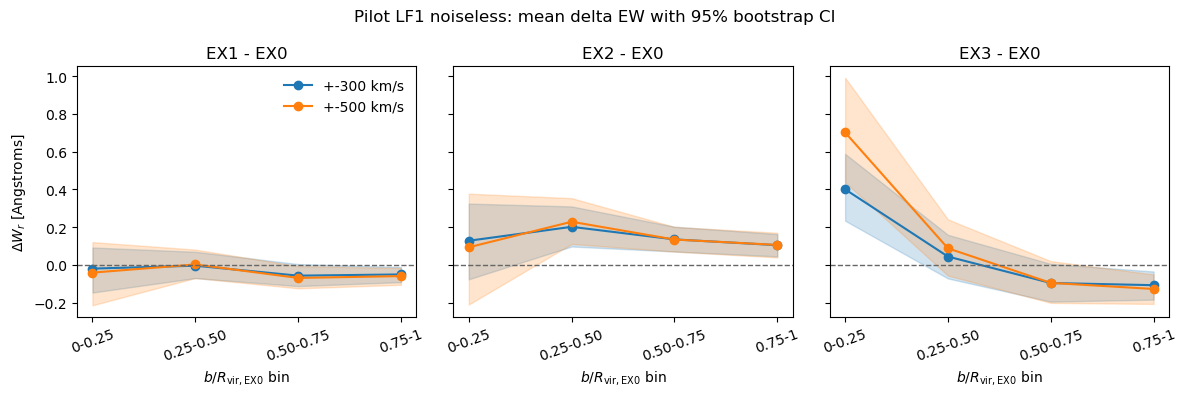

In [81]:
# Display and plot the bootstrap results
lp1_ci = ew_ci.xs("lp1_clean", level="condition") # Select only the LP1-clean condition for plotting
display(lp1_ci.reset_index().round(4)) # Display the bootstrap results rounded to 4 decimal places

fig, axes = plt.subplots(1, 3, figsize=(12, 4), sharey=True)
x = np.arange(4) # The 4 radial bins
bin_labels = ["0-0.25", "0.25-0.50", "0.50-0.75", "0.75-1"] # Labels for the radial bins

for ax, model in zip(axes, ["EX_1", "EX_2", "EX_3"]):
    for window, color in [(300, "C0"), (500, "C1")]:
        rows = lp1_ci.xs((window, model), level=["half_window_kms", "model"]).reindex(x)
        ax.plot(x, rows["mean_delta_A"], "o-", color=color, label=f"+-{window} km/s")
        ax.fill_between(x, rows["ci_low_A"].to_numpy(), rows["ci_high_A"].to_numpy(), color=color, alpha=0.2)
    ax.axhline(0, color="0.4", linestyle="--", linewidth=1)
    ax.set_title(f"{model.replace('_', '')} - EX0")
    ax.set_xticks(x)
    ax.set_xticklabels(bin_labels, rotation=20)
    ax.set_xlabel(r"$b/R_{\rm vir,EX0}$ bin")

axes[0].set_ylabel(r"$\Delta W_r$ [Angstroms]")
axes[0].legend(frameon=False)
fig.suptitle("Pilot LF1 noiseless: mean delta EW with 95% bootstrap CI")
fig.tight_layout()

for ext in [".png", ".pdf"]:
    fig.savefig(FIG_ROOT / f"pilot_ew_bootstrap_z0{ext}", dpi=180, bbox_inches="tight")
plt.show()

# Checking and comparing the same results after removing the large offset (>Rvir) halos

In [ ]:
flagged_ids = [6, 30, 218, 369, 517]
keep = ~delta_by_halo.index.isin(flagged_ids)

type_weights = halo_type.value_counts(normalize=True).sort_index() # Get the proportion of each halo type (star-forming and low_sSFR) sorted by type
cut_rng = np.random.default_rng(seed) # Create a new random number generator with the same seed for reproducibility
cut_mean = np.zeros(values.shape[1]) # Initialize an array to hold the mean delta EW after cutting flagged halos
cut_boot = np.zeros((N_BOOT, values.shape[1])) # Initialize an array to hold the bootstrap means after cutting flagged halos
retained_counts = {}

for type, weight in type_weights.items():
    pos = np.flatnonzero(keep & (halo_type.to_numpy() == type)) # Get the indices of halos of the current type that are not flagged
    retained_counts[str(type)] = len(pos) # Store the count of retained halos of this type
    assert len(pos) > 0, f"No halos of type {type} remain after cutting flagged IDs"

    cut_mean += weight * values[pos].mean(axis=0) # Compute the weighted mean delta EW for the retained halos of this type
    cut_draws = cut_rng.choice(pos, size=(N_BOOT, len(pos)), replace=True) # Generate bootstrap samples for the retained halos of this type
    cut_boot += weight * np.array([values[draw].mean(axis=0) for draw in cut_draws]) # Compute the weighted bootstrap means for the retained halos of this type

cut_low, cut_high = np.quantile(cut_boot, [0.025, 0.975], axis=0) # Compute the 2.5th and 97.5th percentiles for the bootstrap means after cutting flagged halos
cut_ci = pd.DataFrame(
    {
        "mean_delta_A": cut_mean,
        "ci_low_A": cut_low,
        "ci_high_A": cut_high,
    },
    index=delta_by_halo.columns,
).reorder_levels(["half_window_kms", "b_bin", "condition", "model"]).sort_index()

comparison = pd.concat(
    {
        "all_pilots": ew_ci.assign(n_halos=len(values)),
        "offset_cut": cut_ci.assign(n_halos=int(keep.sum())),
    },
    names=["sample"],
)
comparison.to_csv(OUT_ROOT / "pilot_ew_offset_sensitivity_z0.csv")
(OUT_ROOT / "pilot_ew_offset_sensitivity_z0.json").write_text(
    json.dumps({
        "excluded_group_ids": flagged_ids,
        "criterion": "central-position offset > EX0 Rvir",
        "fixed_type_weights": {str(k): float(v) for k, v in type_weights.items()},
        "retained_counts": retained_counts,
        "n_boot": N_BOOT,
        "seed": seed,
        "interval": "pointwise 95% CI",
    }, indent=2) + "\n"
)

print(f"Pilot halos: {len(values)}; after cutting flagged IDs: {(keep.sum())}")
print("Retained counts by type in EX0:", retained_counts)

display(
    comparison.xs(
        ("lp1_clean", "EX_3"), level=["condition", "model"] # Checking EX3 first since it has the largest differences from EX0
    ).reset_index().sort_values(["half_window_kms", "b_bin", "sample"]).round(4)
)

Pilot halos: 20; after cutting flagged IDs: 15
Retained counts by type in EX0: {'low_sSFR': 7, 'star-forming': 8}


,sample,half_window_kms,b_bin,mean_delta_A,ci_low_A,ci_high_A,n_halos
0,all_pilots,300,0,0.4006,0.2341,0.5886,20
8,offset_cut,300,0,0.4887,0.2920,0.7052,15
1,all_pilots,300,1,0.0442,-0.0719,0.1593,20
9,offset_cut,300,1,0.0843,-0.0611,0.2188,15
2,all_pilots,300,2,-0.0960,-0.1946,0.0056,20
10,offset_cut,300,2,-0.0982,-0.2212,0.0345,15
3,all_pilots,300,3,-0.1075,-0.1841,-0.0348,20
11,offset_cut,300,3,-0.1228,-0.2174,-0.0299,15
4,all_pilots,500,0,0.7021,0.4378,0.9918,20
12,offset_cut,500,0,0.8302,0.5237,1.1565,15


# Adding NOISE

In [84]:
SNR_VALS = (20, 50)
NOISE_SEEDS = (42, 43, 44)

def ew_noise_sigma(edges, galaxy_vel, window, sigma_flux):
    """EW error [Å] for independent, constatnt flux error sigma per pixel"""
    box = edges[-1] - edges[0]
    centers = np.atleast_1d(galaxy_vel)
    centers = ((centers - edges[0]) % box + edges[0])[:, None] # Ensure centers are within the box and have shape (N, 1)
    weights = np.zeros((len(centers), len(edges) - 1)) 

    for shift in (-box, 0.0, box):
        left = np.maximum(edges[:-1] + shift, centers - window)
        right = np.minimum(edges[1:] + shift, centers + window)
        weights += np.maximum(0.0, right - left)

    return (1215.67 / 299792.458) * sigma_flux * np.sqrt(np.sum(weights**2, axis=1)) # Convert to Å using the rest wavelength of Lyα and speed of light

noise_frames = []

for model in models:
    data = pilot[model]
    rays = data["rays"]
    flux = data["lp1_flux"]
    edges = data["lp1_edges"]
    galaxy_v = rays["galaxy_velocity_kms"].to_numpy()

    base_frame = rays[[
        "group_id_EX0", "b_bin", "b_over_Rvir_EX0",
        "mass_bin", "type_EX0", "area_weight",
    ]].reset_index()

    window_terms = {}
    for window in (300, 500):
        window_terms[window] = (rest_ew(flux, edges, galaxy_v, window), ew_noise_sigma(edges, galaxy_v, window, 1.0))

    for seed in NOISE_SEEDS:
        noise_rng = np.random.default_rng([seed, int(model.split("_")[-1])]) # Use model number as part of the seed for reproducibility
        standard_noise = noise_rng.standard_normal(flux.shape) # Generate standard normal noise for the flux array

        for snr in SNR_VALS:
            sigma_flux = np.sqrt(2.0) / snr
            noisy_flux = flux + sigma_flux * standard_noise

            for window, (clean_W, unit_sigma_W) in window_terms.items():
                frame = base_frame.copy()
                frame["model"] = model
                frame["condition"] = f"lp1_snr{snr}"
                frame["snr_resel"] = snr
                frame["noise_seed"] = seed
                frame["half_window_kms"] = window
                frame["sigma_flux"] = sigma_flux
                frame["W_r_clean_A"] = clean_W
                frame["sigma_W_A"] = sigma_flux * unit_sigma_W
                frame["W_r_A"] = rest_ew(
                    noisy_flux, edges, galaxy_v, window
                )
                frame["noise_delta_A"] = frame["W_r_A"] - clean_W
                noise_frames.append(frame)

noisy_ew = pd.concat(noise_frames, ignore_index=True)
noisy_ew.to_csv(
    OUT_ROOT / "pilot_equivalent_widths_noisy_z0.csv", index=False
)
(OUT_ROOT / "pilot_equivalent_widths_noisy_z0.json").write_text(
    json.dumps({
        "snr_resel": list(SNR_VALS),
        "noise_seeds": list(NOISE_SEEDS),
        "half_windows_kms": [300, 500],
        "noise_model": "independent additive Gaussian after LP1 and rebinning",
        "sigma_flux": "sqrt(2) / SNR_resel",
        "independent_noise_between_models": True,
        "same_standard_noise_across_snr": True,
        "flux_clipped": False,
        "continuum": "known exactly",
    }, indent=2) + "\n"
)

noise_summary = noisy_ew.groupby(
    ["snr_resel", "half_window_kms"]
).agg(
    median_sigma_W_A=("sigma_W_A", "median"),
    mean_noise_shift_A=("noise_delta_A", "mean"),
    rms_noise_shift_A=(
        "noise_delta_A", lambda x: np.sqrt(np.mean(x**2))
    ),
)
display(noise_summary.reset_index().round(5))  

,snr_resel,half_window_kms,median_sigma_W_A,mean_noise_shift_A,rms_noise_shift_A
0,20,300,0.01842,0.00003,0.01878
1,20,500,0.02380,-0.00025,0.02405
2,50,300,0.00737,0.00001,0.00751
3,50,500,0.00952,-0.00010,0.00962


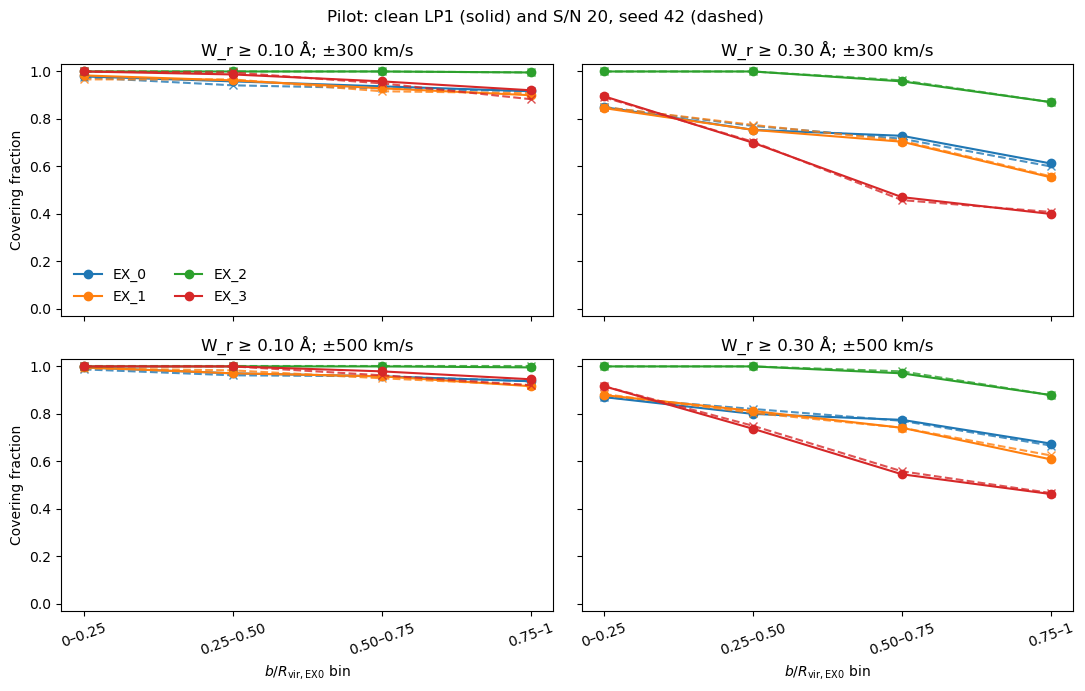

model,W_cut_A,half_window_kms,b_bin,EX_1,EX_2,EX_3
0,0.1,300,0,-0.008,0.025,0.025
1,0.1,300,1,0.025,0.058,0.054
2,0.1,300,2,-0.012,0.071,0.021
3,0.1,300,3,-0.008,0.079,-0.033
4,0.1,500,0,0.004,0.012,0.012
5,0.1,500,1,0.021,0.037,0.037
6,0.1,500,2,-0.008,0.042,0.004
7,0.1,500,3,-0.017,0.062,-0.017
8,0.3,300,0,0.000,0.150,0.042
9,0.3,300,1,0.004,0.229,-0.067


In [85]:
W_CUTS_A = (0.10, 0.30)
PLOT_SEED = 42

# Both thresholds exceed the nominal 3-sigma EW error for every ray.
assert (3.0 * noisy_ew["sigma_W_A"] < min(W_CUTS_A)).all()

clean_cf = ew_table.loc[ew_table["condition"].eq("lp1_clean")].copy()
clean_cf["noise_seed"] = -1  # Sentinel for the noiseless measurements.
cf_input = pd.concat([clean_cf, noisy_ew], ignore_index=True)

group_cols = [
    "W_cut_A", "half_window_kms", "b_bin", "condition",
    "noise_seed", "group_id_EX0", "model",
]
cf_parts = []

for cut in W_CUTS_A:
    frame = cf_input.assign(
        W_cut_A=cut,
        covered=cf_input["W_r_A"].ge(cut),
    )
    cf_parts.append(
        frame.groupby(group_cols, observed=True)
        .agg(f_cover=("covered", "mean"), n_rays=("covered", "size"))
        .reset_index()
    )

cf_halo = pd.concat(cf_parts, ignore_index=True)
assert cf_halo["n_rays"].eq(12).all()

# Equal halo weights within each radial bin; each seed stays separate.
summary_cols = [c for c in group_cols if c != "group_id_EX0"]
cf_summary = (
    cf_halo.groupby(summary_cols, observed=True)
    .agg(f_cover=("f_cover", "mean"), n_halos=("f_cover", "size"))
    .reset_index()
)
cf_wide = cf_summary.pivot(
    index=[c for c in summary_cols if c != "model"],
    columns="model", values="f_cover",
)
cf_delta = cf_wide[["EX_1", "EX_2", "EX_3"]].sub(
    cf_wide["EX_0"], axis=0
)

cf_halo.to_csv(OUT_ROOT / "pilot_covering_fractions_per_halo_z0.csv",
               index=False)
cf_summary.to_csv(OUT_ROOT / "pilot_covering_fractions_z0.csv",
                  index=False)
cf_delta.to_csv(OUT_ROOT / "pilot_delta_covering_fractions_z0.csv")
(OUT_ROOT / "pilot_covering_fractions_z0.json").write_text(
    json.dumps({
        "W_cuts_A": list(W_CUTS_A),
        "criterion": "W_r_A >= W_cut_A",
        "denominator": "all 12 rays in each halo and radial bin",
        "halo_weighting": "equal within the selected pilot",
        "clean_noise_seed": -1,
        "noise_seeds_kept_separate": True,
        "plot_condition": "lp1_snr20",
        "plot_noise_seed": PLOT_SEED,
    }, indent=2) + "\n"
)

fig, axes = plt.subplots(2, 2, figsize=(11, 7), sharex=True, sharey=True)
x = np.arange(4)
bin_labels = ["0–0.25", "0.25–0.50", "0.50–0.75", "0.75–1"]

for row, window in enumerate((300, 500)):
    for col, cut in enumerate(W_CUTS_A):
        ax = axes[row, col]
        clean_rows = cf_wide.xs(
            (cut, window, "lp1_clean", -1),
            level=["W_cut_A", "half_window_kms", "condition", "noise_seed"],
        ).reindex(x)
        noisy_rows = cf_wide.xs(
            (cut, window, "lp1_snr20", PLOT_SEED),
            level=["W_cut_A", "half_window_kms", "condition", "noise_seed"],
        ).reindex(x)

        for i, model in enumerate(models):
            ax.plot(x, clean_rows[model], "o-", color=f"C{i}", label=model)
            ax.plot(x, noisy_rows[model], "x--", color=f"C{i}", alpha=0.8)

        ax.set_title(f"W_r ≥ {cut:.2f} Å; ±{window} km/s")
        ax.set_ylim(-0.03, 1.03)
        ax.set_xticks(x)
        ax.set_xticklabels(bin_labels, rotation=20)

for ax in axes[:, 0]:
    ax.set_ylabel("Covering fraction")
for ax in axes[-1]:
    ax.set_xlabel(r"$b/R_{\mathrm{vir,EX0}}$ bin")
axes[0, 0].legend(frameon=False, ncol=2)
fig.suptitle(
    f"Pilot: clean LP1 (solid) and S/N 20, seed {PLOT_SEED} (dashed)"
)
fig.tight_layout()
for suffix in ("png", "pdf"):
    fig.savefig(OUT_ROOT / "figures" / f"pilot_covering_fractions_z0.{suffix}",
                dpi=180, bbox_inches="tight")
plt.show()

display(
    cf_delta.xs(
        ("lp1_snr20", PLOT_SEED), level=["condition", "noise_seed"]
    ).reset_index().round(3)
)

In [86]:
FULL_OUT_ROOT = CODE_ROOT / "outputs/galaxy_absorption/full"
(FULL_OUT_ROOT / "figures").mkdir(parents=True, exist_ok=True)

full = {}
full_loaded = []

for model in models:
    path = SPEC_ROOT / f"galaxy_full_{model}_090.hdf5"

    with h5py.File(path, "r") as handle:
        tau = handle["tau/H/1/1215"][:]
        md = handle["galaxy_metadata"]
        rays = pd.read_csv(io.StringIO(md["manifest_csv"].asstr()[()]))

        assert len(rays) == len(tau) == 11856
        assert rays["group_id_EX0"].nunique() == 247
        assert np.array_equal(rays["ray_id"].to_numpy(), md["ray_id"][:])

        vmax = float(md.attrs["vmax_kms"])
        velfac = float(md.attrs["velfac_kms_per_ckpch"])

    rays["spectrum_row"] = np.arange(len(rays))
    rays["galaxy_velocity_kms"] = (
        velfac * rays["galaxy_los_ckpch"] + rays["galaxy_vlos_kms"]
    ) % vmax

    full[model] = {
        "rays": rays.set_index("ray_id"),
        "flux": np.exp(-tau),
        "edges": np.linspace(0, vmax, tau.shape[1] + 1),
        "vmax": vmax,
    }

    full_loaded.append({
        "model": model,
        "n_halos": rays["group_id_EX0"].nunique(),
        "n_rays": tau.shape[0],
        "n_pixels": tau.shape[1],
        "dv_kms": vmax / tau.shape[1],
    })

del tau
display(pd.DataFrame(full_loaded).set_index("model").round(4))

,n_halos,n_rays,n_pixels,dv_kms
model,,,,
EX_0,247,11856,2499,1.0004
EX_1,247,11856,2499,1.0004
EX_2,247,11856,2499,1.0004
EX_3,247,11856,2499,1.0004


In [87]:
HALF_WINDOWS = (300, 500)
SNR_VALUES = (20, 50)
NOISE_SEEDS = (42, 43, 44)
W_CUTS_A = (0.10, 0.30)
BLOCK_RAYS = 512

full_frames = []
full_lsf_metadata = {}
meta_cols = [
    "group_id_EX0", "b_bin", "b_over_Rvir_EX0",
    "mass_bin", "type_EX0", "area_weight",
]

for model in models:
    data = full[model]
    rays = data["rays"]
    dv_native = data["vmax"] / data["flux"].shape[1]
    lp1_blocks = []
    noise_rngs = {
        seed: np.random.default_rng([seed, int(model.split("_")[-1])])
        for seed in NOISE_SEEDS
    }

    for start in range(0, len(rays), BLOCK_RAYS):
        stop = min(start + BLOCK_RAYS, len(rays))
        rows = rays.iloc[start:stop]
        base_frame = rows[meta_cols].reset_index()
        galaxy_v = rows["galaxy_velocity_kms"].to_numpy()
        native = np.asarray(data["flux"][start:stop], dtype=np.float64)

        lp1, dv_lp1, lsf_meta = cos_forward.prepare_lp1_flux(
            native, dv_sim=dv_native, lsf_path=LSF_PATH
        )
        np.testing.assert_allclose(
            lp1.mean(axis=1), native.mean(axis=1), rtol=0, atol=1e-11
        )
        lp1_edges = np.linspace(0, data["vmax"], lp1.shape[1] + 1)
        lp1_blocks.append(lp1)
        standard_noise = {
            seed: noise_rngs[seed].standard_normal(lp1.shape)
            for seed in NOISE_SEEDS
        }

        for window in HALF_WINDOWS:
            native_W = rest_ew(native, data["edges"], galaxy_v, window)
            lp1_W = rest_ew(lp1, lp1_edges, galaxy_v, window)
            unit_sigma_W = ew_noise_sigma(lp1_edges, galaxy_v, window, 1.0)

            # Entries: condition, seed, S/N, EW, EW noise error.
            entries = [
                ("native", -1, np.inf, native_W, 0.0),
                ("lp1_clean", -1, np.inf, lp1_W, 0.0),
            ]
            for seed in NOISE_SEEDS:
                for snr in SNR_VALUES:
                    sigma_flux = np.sqrt(2.0) / snr
                    noisy_W = rest_ew(
                        lp1 + sigma_flux * standard_noise[seed],
                        lp1_edges, galaxy_v, window,
                    )
                    entries.append((
                        f"lp1_snr{snr}", seed, snr, noisy_W,
                        sigma_flux * unit_sigma_W,
                    ))

            for condition, seed, snr, W, sigma_W in entries:
                frame = base_frame.copy()
                frame["model"] = model
                frame["condition"] = condition
                frame["noise_seed"] = seed
                frame["snr_resel"] = snr
                frame["half_window_kms"] = window
                frame["W_r_A"] = W
                frame["sigma_W_A"] = sigma_W
                full_frames.append(frame)

    data["lp1_flux"] = np.concatenate(lp1_blocks, axis=0)
    data["lp1_edges"] = lp1_edges
    full_lsf_metadata[model] = lsf_meta
    print(f"Completed {model}: {len(rays):,} rays")

full_ew = pd.concat(full_frames, ignore_index=True)
del full_frames
full_ew["covered_010"] = full_ew["W_r_A"].ge(W_CUTS_A[0])
full_ew["covered_030"] = full_ew["W_r_A"].ge(W_CUTS_A[1])

halo_keys = [
    "group_id_EX0", "mass_bin", "type_EX0", "b_bin",
    "model", "condition", "noise_seed", "half_window_kms",
]
full_halo = (
    full_ew.groupby(halo_keys, observed=True)
    .agg(
        W_r_A=("W_r_A", "mean"),
        fc_010=("covered_010", "mean"),
        fc_030=("covered_030", "mean"),
        n_rays=("ray_id", "size"),
    ).reset_index()
)
assert full_halo["n_rays"].eq(12).all()

full_ew.to_csv(FULL_OUT_ROOT / "measurements_z0.csv.gz", index=False)
full_halo.to_csv(FULL_OUT_ROOT / "halo_measurements_z0.csv", index=False)
(FULL_OUT_ROOT / "measurement_settings_z0.json").write_text(
    json.dumps({
        "tau_multiplier": 1.0,
        "half_windows_kms": list(HALF_WINDOWS),
        "W_cuts_A": list(W_CUTS_A),
        "snr_resel": list(SNR_VALUES),
        "noise_seeds": list(NOISE_SEEDS),
        "clean_noise_seed": -1,
        "noise_sigma_flux": "sqrt(2) / SNR_resel",
        "independent_noise_between_models": True,
        "same_standard_noise_across_snr": True,
        "flux_clipped": False,
        "continuum": "known exactly",
        "lsf_by_model": full_lsf_metadata,
    }, indent=2) + "\n"
)

# First view: S/N 20, seed 42, +/-300 km/s, separately by EX0 type.
selected = full_halo.loc[
    full_halo["condition"].eq("lp1_snr20")
    & full_halo["noise_seed"].eq(42)
    & full_halo["half_window_kms"].eq(300)
]
type_means = selected.groupby(
    ["type_EX0", "b_bin", "model"], observed=True
).agg(
    W_r_A=("W_r_A", "mean"),
    fc_010=("fc_010", "mean"),
    fc_030=("fc_030", "mean"),
    n_halos=("group_id_EX0", "nunique"),
)
type_wide = type_means[["W_r_A", "fc_010", "fc_030"]].unstack("model")
reference = type_wide.xs("EX_0", level="model", axis=1)
type_frames = []

for model in ["EX_1", "EX_2", "EX_3"]:
    difference = type_wide.xs(model, level="model", axis=1) - reference
    difference["model"] = model
    difference["n_halos"] = type_means["n_halos"].xs("EX_0", level="model")
    type_frames.append(difference.reset_index())

full_type_delta = pd.concat(type_frames, ignore_index=True).rename(columns={
    "W_r_A": "delta_W_A",
    "fc_010": "delta_fc_010",
    "fc_030": "delta_fc_030",
})
full_type_delta = full_type_delta[[
    "type_EX0", "b_bin", "model", "n_halos",
    "delta_W_A", "delta_fc_010", "delta_fc_030",
]].sort_values(["type_EX0", "b_bin", "model"])
full_type_delta.to_csv(
    FULL_OUT_ROOT / "type_deltas_snr20_seed42_v300_z0.csv", index=False
)
display(full_type_delta.round(4))

Completed EX_0: 11,856 rays
Completed EX_1: 11,856 rays
Completed EX_2: 11,856 rays
Completed EX_3: 11,856 rays


,type_EX0,b_bin,model,n_halos,delta_W_A,delta_fc_010,delta_fc_030
0,low_sSFR,0,EX_1,59,-0.2025,-0.0381,-0.1271
8,low_sSFR,0,EX_2,59,0.3354,0.0636,0.2952
16,low_sSFR,0,EX_3,59,0.5368,0.0452,0.1116
1,low_sSFR,1,EX_1,59,-0.0841,-0.0621,-0.1186
9,low_sSFR,1,EX_2,59,0.2778,0.0960,0.4011
17,low_sSFR,1,EX_3,59,0.0091,0.0607,-0.0452
2,low_sSFR,2,EX_1,59,-0.0853,-0.0805,-0.1257
10,low_sSFR,2,EX_2,59,0.1993,0.1144,0.3531
18,low_sSFR,2,EX_3,59,-0.0567,0.0410,-0.1370
3,low_sSFR,3,EX_1,59,-0.0938,-0.0862,-0.1624


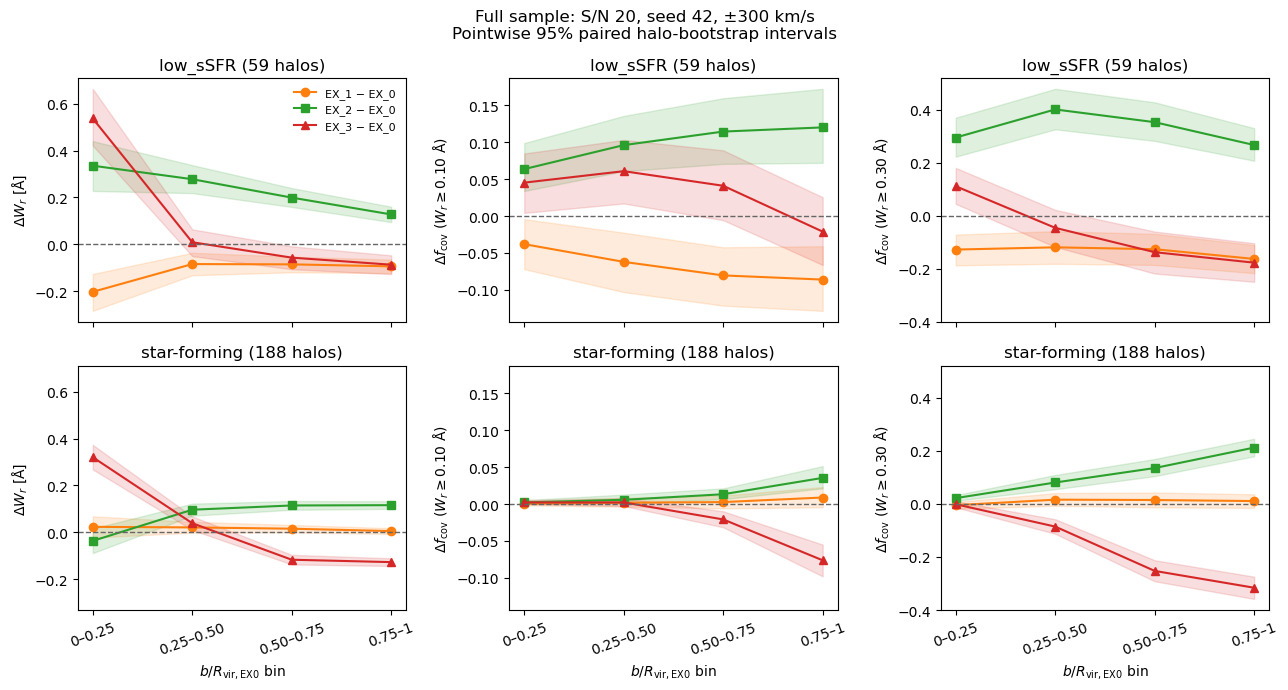

,type_EX0,b_bin,model,n_halos,mean_delta,ci_low,ci_high
130,low_sSFR,0,EX_1,59,-0.1271,-0.1864,-0.0706
322,low_sSFR,0,EX_2,59,0.2952,0.2232,0.3701
514,low_sSFR,0,EX_3,59,0.1116,0.0452,0.1808
146,low_sSFR,1,EX_1,59,-0.1186,-0.1808,-0.0579
338,low_sSFR,1,EX_2,59,0.4011,0.3262,0.4788
530,low_sSFR,1,EX_3,59,-0.0452,-0.1172,0.0226
162,low_sSFR,2,EX_1,59,-0.1257,-0.1850,-0.0678
354,low_sSFR,2,EX_2,59,0.3531,0.2825,0.4280
546,low_sSFR,2,EX_3,59,-0.1370,-0.2175,-0.0593
178,low_sSFR,3,EX_1,59,-0.1624,-0.2161,-0.1101


In [88]:
FULL_N_BOOT = 5000
FULL_BOOT_SEED = 42
METRICS = ["W_r_A", "fc_010", "fc_030"]
OTHER_MODELS = ["EX_1", "EX_2", "EX_3"]

# One row per halo; columns contain measured model/condition combinations.
measurement_cols = ["b_bin", "condition", "noise_seed", "half_window_kms"]
full_wide = full_halo.pivot(
    index="group_id_EX0",
    columns=["model", *measurement_cols],
    values=METRICS,
).sort_index()
full_wide.columns.names = ["metric", "model", *measurement_cols]

full_reference = full_wide.xs("EX_0", level="model", axis=1)
full_delta_by_halo = pd.concat({
    model: full_wide.xs(model, level="model", axis=1) - full_reference
    for model in OTHER_MODELS
}, axis=1)
full_delta_by_halo.columns.names = ["model", "metric", *measurement_cols]

full_meta = (
    full_halo[["group_id_EX0", "type_EX0", "mass_bin"]]
    .drop_duplicates()
    .set_index("group_id_EX0")
    .reindex(full_delta_by_halo.index)
)

full_boot_rng = np.random.default_rng(FULL_BOOT_SEED)
ci_frames = []

for kind in ["low_sSFR", "star-forming"]:
    group_values = full_delta_by_halo.loc[
        full_meta["type_EX0"].eq(kind)
    ].to_numpy()
    assert np.isfinite(group_values).all()
    n_halos = len(group_values)

    full_draws = full_boot_rng.integers(
        0, n_halos, size=(FULL_N_BOOT, n_halos)
    )
    # Process each resample separately to avoid a large temporary array.
    boot_means = np.array([
        group_values[draw].mean(axis=0) for draw in full_draws
    ])
    low, high = np.quantile(boot_means, [0.025, 0.975], axis=0)

    result = pd.DataFrame({
        "mean_delta": group_values.mean(axis=0),
        "ci_low": low,
        "ci_high": high,
        "constant_across_halos": np.ptp(group_values, axis=0) == 0,
    }, index=full_delta_by_halo.columns).reset_index()
    result["type_EX0"] = kind
    result["n_halos"] = n_halos
    ci_frames.append(result)

full_type_ci = pd.concat(ci_frames, ignore_index=True)
full_type_ci.to_csv(FULL_OUT_ROOT / "type_bootstrap_z0.csv", index=False)
(FULL_OUT_ROOT / "type_bootstrap_z0.json").write_text(
    json.dumps({
        "n_boot": FULL_N_BOOT,
        "seed": FULL_BOOT_SEED,
        "resampling_unit": "group_id_EX0",
        "resampling_within": "type_EX0",
        "interval": "pointwise 95% percentile",
        "noise_seeds_kept_separate": True,
        "type_counts": {
            str(k): int(v)
            for k, v in full_meta["type_EX0"].value_counts().items()
        },
    }, indent=2) + "\n"
)

ci_view = full_type_ci.loc[
    full_type_ci["condition"].eq("lp1_snr20")
    & full_type_ci["noise_seed"].eq(42)
    & full_type_ci["half_window_kms"].eq(300)
]

fig, axes = plt.subplots(
    2, 3, figsize=(13, 7), sharex=True, sharey="col"
)
x = np.arange(4)
bin_labels = ["0–0.25", "0.25–0.50", "0.50–0.75", "0.75–1"]
metric_labels = {
    "W_r_A": r"$\Delta W_r$ [Å]",
    "fc_010": r"$\Delta f_{\rm cov}$ ($W_r\geq0.10$ Å)",
    "fc_030": r"$\Delta f_{\rm cov}$ ($W_r\geq0.30$ Å)",
}

for row, kind in enumerate(["low_sSFR", "star-forming"]):
    n = int(full_meta["type_EX0"].eq(kind).sum())
    for col, metric in enumerate(METRICS):
        ax = axes[row, col]
        for model, color, marker in [
            ("EX_1", "C1", "o"),
            ("EX_2", "C2", "s"),
            ("EX_3", "C3", "^"),
        ]:
            rows = ci_view.loc[
                ci_view["type_EX0"].eq(kind)
                & ci_view["metric"].eq(metric)
                & ci_view["model"].eq(model)
            ].set_index("b_bin").reindex(x)

            ax.plot(x, rows["mean_delta"], color=color, marker=marker,
                    label=f"{model} − EX_0")
            ax.fill_between(x, rows["ci_low"].to_numpy(),
                            rows["ci_high"].to_numpy(),
                            color=color, alpha=0.15)

        ax.axhline(0, color="0.4", linestyle="--", linewidth=1)
        ax.set_title(f"{kind} ({n} halos)")
        ax.set_ylabel(metric_labels[metric])
        ax.set_xticks(x)
        ax.set_xticklabels(bin_labels, rotation=20)

for ax in axes[-1]:
    ax.set_xlabel(r"$b/R_{\mathrm{vir,EX0}}$ bin")
axes[0, 0].legend(frameon=False, fontsize=8)
fig.suptitle(
    "Full sample: S/N 20, seed 42, ±300 km/s\n"
    "Pointwise 95% paired halo-bootstrap intervals"
)
fig.tight_layout()

for suffix in ("png", "pdf"):
    fig.savefig(
        FULL_OUT_ROOT / "figures" / f"type_bootstrap_snr20_z0.{suffix}",
        dpi=180, bbox_inches="tight",
    )
plt.show()

display(
    ci_view.loc[ci_view["metric"].eq("fc_030"), [
        "type_EX0", "b_bin", "model", "n_halos",
        "mean_delta", "ci_low", "ci_high",
    ]].sort_values(["type_EX0", "b_bin", "model"]).round(4)
)

In [89]:
MASS_BIN = "12-12.5"
MASS_N_BOOT = 5000
MASS_BOOT_SEED = 42

mass_rng = np.random.default_rng(MASS_BOOT_SEED)
mass_means, mass_boot, mass_counts, mass_frames = {}, {}, {}, {}


def mass_ci_frame(point, boot):
    lo, hi = np.quantile(boot, [0.025, 0.975], axis=0)
    return pd.DataFrame(
        {"mean_delta": point, "ci_low": lo, "ci_high": hi},
        index=full_delta_by_halo.columns,
    ).reset_index()


for kind in ["low_sSFR", "star-forming"]:
    mass_keep = (
        full_meta["mass_bin"].eq(MASS_BIN)
        & full_meta["type_EX0"].eq(kind)
    )
    mass_values = full_delta_by_halo.loc[mass_keep].to_numpy()
    mass_n = len(mass_values)

    assert mass_n >= 2 and np.isfinite(mass_values).all()
    mass_counts[kind] = mass_n
    mass_means[kind] = mass_values.mean(axis=0)

    # Resample whole halos; use each draw across all measurement columns.
    mass_draws = mass_rng.integers(
        0, mass_n, size=(MASS_N_BOOT, mass_n)
    )
    mass_boot[kind] = np.array([
        mass_values[draw].mean(axis=0) for draw in mass_draws
    ])

    mass_result = mass_ci_frame(mass_means[kind], mass_boot[kind])
    mass_result["type_EX0"] = kind
    mass_result["n_halos"] = mass_n
    mass_result["mass_bin"] = MASS_BIN
    mass_frames[kind] = mass_result

mass_type_ci = pd.concat(mass_frames.values(), ignore_index=True)

# The two type populations were resampled independently.
mass_type_contrast_ci = mass_ci_frame(
    mass_means["low_sSFR"] - mass_means["star-forming"],
    mass_boot["low_sSFR"] - mass_boot["star-forming"],
).rename(columns={"mean_delta": "mean_type_contrast"})

mass_type_contrast_ci["mass_bin"] = MASS_BIN
mass_type_contrast_ci["n_low_sSFR"] = mass_counts["low_sSFR"]
mass_type_contrast_ci["n_star_forming"] = mass_counts["star-forming"]

mass_type_ci.to_csv(
    FULL_OUT_ROOT / "mass12_12p5_type_bootstrap_z0.csv", index=False
)
mass_type_contrast_ci.to_csv(
    FULL_OUT_ROOT / "mass12_12p5_type_contrast_z0.csv", index=False
)

with (FULL_OUT_ROOT / "mass12_12p5_bootstrap_z0.json").open("w") as f:
    json.dump({
        "mass_bin": MASS_BIN,
        "n_boot": MASS_N_BOOT,
        "bootstrap_seed": MASS_BOOT_SEED,
        "resampling_unit": "group_id_EX0",
        "type_counts": mass_counts,
        "interval": "pointwise 95% percentile",
        "contrast": "low_sSFR model-minus-EX0 minus star-forming model-minus-EX0",
        "noise_seeds": "kept separate",
    }, f, indent=2)


def mass_fc030_view(table):
    return table.loc[
        table["metric"].eq("fc_030")
        & table["condition"].eq("lp1_snr20")
        & table["noise_seed"].eq(42)
        & table["half_window_kms"].eq(300)
    ]


print("Halos in shared mass bin:", mass_counts)

display(
    mass_fc030_view(mass_type_ci)
    .sort_values(["type_EX0", "b_bin", "model"])
    [["type_EX0", "b_bin", "model", "n_halos",
      "mean_delta", "ci_low", "ci_high"]]
    .round(4)
)

display(
    mass_fc030_view(mass_type_contrast_ci)
    .sort_values(["b_bin", "model"])
    [["b_bin", "model", "mean_type_contrast", "ci_low", "ci_high"]]
    .round(4)
)

Halos in shared mass bin: {'low_sSFR': 35, 'star-forming': 29}


,type_EX0,b_bin,model,n_halos,mean_delta,ci_low,ci_high
130,low_sSFR,0,EX_1,35,-0.1833,-0.2738,-0.0952
322,low_sSFR,0,EX_2,35,0.2548,0.1643,0.3500
514,low_sSFR,0,EX_3,35,0.1595,0.0548,0.2643
146,low_sSFR,1,EX_1,35,-0.1357,-0.2357,-0.0381
338,low_sSFR,1,EX_2,35,0.4167,0.3238,0.5119
530,low_sSFR,1,EX_3,35,-0.0857,-0.2000,0.0190
162,low_sSFR,2,EX_1,35,-0.1714,-0.2571,-0.0881
354,low_sSFR,2,EX_2,35,0.4310,0.3405,0.5214
546,low_sSFR,2,EX_3,35,-0.1810,-0.2833,-0.0786
178,low_sSFR,3,EX_1,35,-0.2167,-0.2905,-0.1500


,b_bin,model,mean_type_contrast,ci_low,ci_high
130,0,EX_1,-0.1546,-0.2675,-0.0357
322,0,EX_2,0.1686,0.0679,0.2745
514,0,EX_3,0.1739,0.0543,0.2930
146,1,EX_1,-0.1846,-0.3351,-0.0365
338,1,EX_2,0.1552,0.0103,0.2975
530,1,EX_3,0.0120,-0.1359,0.1631
162,2,EX_1,-0.2691,-0.4124,-0.1325
354,2,EX_2,0.0143,-0.1261,0.1512
546,2,EX_3,-0.0603,-0.2126,0.0998
178,3,EX_1,-0.2914,-0.3998,-0.1838


In [90]:
mass_check = (
    full["EX_0"]["rays"][["group_id_EX0", "M200c_EX0_Msun"]]
    .drop_duplicates("group_id_EX0")
    .set_index("group_id_EX0")
    .join(full_meta[["type_EX0", "mass_bin"]])
)

mass_check = mass_check.loc[
    mass_check["mass_bin"].eq("12-12.5")
].copy()

mass_check["logM200c"] = np.log10(mass_check["M200c_EX0_Msun"])

mass_balance = (
    mass_check.groupby("type_EX0")["logM200c"]
    .agg(
        n_halos="size",
        mean="mean",
        p16=lambda s: s.quantile(0.16),
        median="median",
        p84=lambda s: s.quantile(0.84),
    )
)

# pd.cut assigns each halo to a 0.1-dex interval.
mass_check["fine_mass_bin"] = pd.cut(
    mass_check["logM200c"],
    bins=np.linspace(12.0, 12.5, 6),
    right=False,
)

mass_fine_counts = pd.crosstab(
    mass_check["fine_mass_bin"],
    mass_check["type_EX0"],
    dropna=False,
)

display(mass_balance.round(3))
display(mass_fine_counts)

mass_balance.to_csv(
    FULL_OUT_ROOT / "mass12_12p5_mass_balance_z0.csv"
)
mass_fine_counts.to_csv(
    FULL_OUT_ROOT / "mass12_12p5_fine_mass_counts_z0.csv"
)

,n_halos,mean,p16,median,p84
type_EX0,,,,,
low_sSFR,35,12.25,12.088,12.264,12.432
star-forming,29,12.13,12.039,12.107,12.230


type_EX0,low_sSFR,star-forming
fine_mass_bin,,
"[12.0, 12.1)",7,13
"[12.1, 12.2)",7,9
"[12.2, 12.3)",9,5
"[12.3, 12.4)",3,2
"[12.4, 12.5)",9,0


In [91]:
STD_N_BOOT = 5000
STD_BOOT_SEED = 42
std_types = ["low_sSFR", "star-forming"]
std_rng = np.random.default_rng(STD_BOOT_SEED)

# Keep bins populated by both types; define one common mass distribution.
std_counts = mass_fine_counts.loc[
    mass_fine_counts[std_types].gt(0).all(axis=1), std_types
].copy()
std_weights = std_counts.sum(axis=1) / std_counts.to_numpy().sum()

std_means, std_boot, std_mass_means, std_frames = {}, {}, {}, []

for kind in std_types:
    std_means[kind] = np.zeros(full_delta_by_halo.shape[1])
    std_boot[kind] = np.zeros((STD_N_BOOT, full_delta_by_halo.shape[1]))
    std_mass_means[kind] = 0.0

    for mass_bin, weight in std_weights.items():
        std_ids = mass_check.index[
            mass_check["type_EX0"].eq(kind)
            & mass_check["fine_mass_bin"].eq(mass_bin)
        ]
        std_values = full_delta_by_halo.loc[std_ids].to_numpy()
        std_n = len(std_values)
        assert std_n >= 2 and np.isfinite(std_values).all()

        std_means[kind] += weight * std_values.mean(axis=0)
        std_mass_means[kind] += weight * mass_check.loc[
            std_ids, "logM200c"
        ].mean()

        # Each draw preserves all model, radial-bin, and condition pairings.
        std_draws = std_rng.integers(
            0, std_n, size=(STD_N_BOOT, std_n)
        )
        std_boot[kind] += weight * np.array([
            std_values[draw].mean(axis=0) for draw in std_draws
        ])

    std_result = mass_ci_frame(std_means[kind], std_boot[kind])
    std_result["type_EX0"] = kind
    std_result["n_halos"] = int(std_counts[kind].sum())
    std_frames.append(std_result)

mass_std_type_ci = pd.concat(std_frames, ignore_index=True)

mass_std_contrast_ci = mass_ci_frame(
    std_means["low_sSFR"] - std_means["star-forming"],
    std_boot["low_sSFR"] - std_boot["star-forming"],
).rename(columns={"mean_delta": "mean_type_contrast"})

mass_std_contrast_ci["n_low_sSFR"] = int(std_counts["low_sSFR"].sum())
mass_std_contrast_ci["n_star_forming"] = int(std_counts["star-forming"].sum())

# Save estimates and the exact reference weights.
mass_std_type_ci.to_csv(
    FULL_OUT_ROOT / "mass_standardized_type_bootstrap_z0.csv", index=False
)
mass_std_contrast_ci.to_csv(
    FULL_OUT_ROOT / "mass_standardized_type_contrast_z0.csv", index=False
)
std_counts.assign(target_weight=std_weights).to_csv(
    FULL_OUT_ROOT / "mass_standardized_weights_z0.csv"
)

with (FULL_OUT_ROOT / "mass_standardized_settings_z0.json").open("w") as f:
    json.dump({
        "n_boot": STD_N_BOOT,
        "bootstrap_seed": STD_BOOT_SEED,
        "resampling_unit": "group_id_EX0",
        "strata": ["type_EX0", "fine_mass_bin"],
        "reference": "pooled counts in jointly populated bins; fixed weights",
        "weights_file": "mass_standardized_weights_z0.csv",
        "interval": "pointwise 95% percentile, conditional on reference weights",
        "contrast": "low_sSFR model-minus-EX0 minus star-forming model-minus-EX0",
        "weighted_mean_logM200c": {
            k: float(v) for k, v in std_mass_means.items()
        },
    }, f, indent=2)

print("Weighted mean logM200c:",
      {k: round(v, 4) for k, v in std_mass_means.items()})

display(
    mass_fc030_view(mass_std_type_ci)
    .sort_values(["type_EX0", "b_bin", "model"])
    [["type_EX0", "b_bin", "model", "n_halos",
      "mean_delta", "ci_low", "ci_high"]]
    .round(4)
)

display(
    mass_fc030_view(mass_std_contrast_ci)
    .sort_values(["b_bin", "model"])
    [["b_bin", "model", "mean_type_contrast", "ci_low", "ci_high"]]
    .round(4)
)

Weighted mean logM200c: {'low_sSFR': 12.1536, 'star-forming': 12.1498}


,type_EX0,b_bin,model,n_halos,mean_delta,ci_low,ci_high
130,low_sSFR,0,EX_1,26,-0.2120,-0.3087,-0.1141
322,low_sSFR,0,EX_2,26,0.2076,0.1153,0.3133
514,low_sSFR,0,EX_3,26,0.1362,0.0352,0.2502
146,low_sSFR,1,EX_1,26,-0.2163,-0.3274,-0.1039
338,low_sSFR,1,EX_2,26,0.3609,0.2542,0.4750
530,low_sSFR,1,EX_3,26,-0.1723,-0.3045,-0.0410
162,low_sSFR,2,EX_1,26,-0.2423,-0.3368,-0.1448
354,low_sSFR,2,EX_2,26,0.3786,0.2762,0.4894
546,low_sSFR,2,EX_3,26,-0.2393,-0.3562,-0.1107
178,low_sSFR,3,EX_1,26,-0.2837,-0.3714,-0.1881


,b_bin,model,mean_type_contrast,ci_low,ci_high
130,0,EX_1,-0.1845,-0.3160,-0.0476
322,0,EX_2,0.1063,0.0017,0.2253
514,0,EX_3,0.1521,0.0276,0.2893
146,1,EX_1,-0.2866,-0.4490,-0.1247
338,1,EX_2,0.0643,-0.0883,0.2159
530,1,EX_3,-0.0991,-0.2639,0.0690
162,2,EX_1,-0.3543,-0.4820,-0.2204
354,2,EX_2,-0.0712,-0.2153,0.0789
546,2,EX_3,-0.1432,-0.3043,0.0282
178,3,EX_1,-0.3730,-0.4848,-0.2555


In [92]:
robust_keys = ["half_window_kms", "b_bin", "model"]
robust_cases = ["native", "lp1_clean"] + [
    f"lp1_snr{snr}_s{seed}"
    for snr in [20, 50] for seed in [42, 43, 44]
]

robust_fc = mass_std_contrast_ci.loc[
    mass_std_contrast_ci["metric"].eq("fc_030")
].copy()

robust_fc["case"] = np.where(
    robust_fc["noise_seed"].eq(-1),
    robust_fc["condition"],
    robust_fc["condition"] + "_s" + robust_fc["noise_seed"].astype(str),
)
robust_fc["ci_direction"] = np.select(
    [robust_fc["ci_low"].gt(0), robust_fc["ci_high"].lt(0)],
    ["+", "-"],
    default="0",
)

robust_ci_matrix = robust_fc.pivot(
    index=robust_keys, columns="case", values="ci_direction"
).reindex(columns=robust_cases)

robust_delta = robust_fc.pivot(
    index=robust_keys, columns="case", values="mean_type_contrast"
).reindex(columns=robust_cases)

# Absolute changes in the estimated type contrast, in percentage points.
robust_shifts = pd.DataFrame(index=robust_delta.index)
robust_shifts["native_to_LP1_pp"] = 100 * (
    robust_delta["lp1_clean"] - robust_delta["native"]
).abs()

for snr in [20, 50]:
    robust_noise_cols = [
        f"lp1_snr{snr}_s{seed}" for seed in [42, 43, 44]
    ]
    robust_shifts[f"SNR{snr}_max_shift_pp"] = 100 * (
        robust_delta[robust_noise_cols]
        .sub(robust_delta["lp1_clean"], axis=0)
        .abs()
        .max(axis=1)
    )

# Largest shift across radial bins, and across seeds for noisy conditions.
robust_max_shifts = robust_shifts.groupby(
    level=["half_window_kms", "model"]
).max()

robust_labels = {"native": "Native", "lp1_clean": "LP1 clean"}
robust_labels.update({
    f"lp1_snr{snr}_s{seed}": f"{snr}/{seed}"
    for snr in [20, 50] for seed in [42, 43, 44]
})

robust_ci_matrix.to_csv(
    FULL_OUT_ROOT / "mass_standardized_ci_directions_fc030_z0.csv"
)
robust_shifts.to_csv(
    FULL_OUT_ROOT / "mass_standardized_shifts_fc030_z0.csv"
)

for window in [300, 500]:
    print(f"Half-window: {window} km/s")
    display(
        robust_ci_matrix.xs(window, level="half_window_kms")
        .rename(columns=robust_labels)
        .rename_axis(columns=None)
        .reset_index()
    )

print("Largest absolute shifts in type contrast (percentage points):")
display(robust_max_shifts.reset_index().round(2))

Half-window: 300 km/s


,b_bin,model,Native,LP1 clean,20/42,20/43,20/44,50/42,50/43,50/44
0,0,EX_1,-,-,-,-,-,-,-,-
1,0,EX_2,0,0,+,+,0,+,0,+
2,0,EX_3,+,+,+,+,+,+,+,+
3,1,EX_1,-,-,-,-,-,-,-,-
4,1,EX_2,0,0,0,0,0,0,0,0
5,1,EX_3,0,0,0,0,0,0,0,0
6,2,EX_1,-,-,-,-,-,-,-,-
7,2,EX_2,0,0,0,0,0,0,0,0
8,2,EX_3,0,0,0,0,0,0,0,0
9,3,EX_1,-,-,-,-,-,-,-,-


Half-window: 500 km/s


,b_bin,model,Native,LP1 clean,20/42,20/43,20/44,50/42,50/43,50/44
0,0,EX_1,-,-,-,-,-,-,-,-
1,0,EX_2,+,+,0,0,+,0,0,0
2,0,EX_3,+,+,+,+,+,+,+,+
3,1,EX_1,-,-,-,-,-,-,-,-
4,1,EX_2,0,0,0,0,0,0,0,0
5,1,EX_3,0,0,0,0,0,0,0,0
6,2,EX_1,-,-,-,-,-,-,-,-
7,2,EX_2,0,0,0,0,0,0,0,0
8,2,EX_3,-,-,-,0,-,0,0,-
9,3,EX_1,-,-,-,-,-,-,-,-


Largest absolute shifts in type contrast (percentage points):


,half_window_kms,model,native_to_LP1_pp,SNR20_max_shift_pp,SNR50_max_shift_pp
0,300,EX_1,0.86,2.47,2.11
1,300,EX_2,0.43,3.04,1.44
2,300,EX_3,0.43,2.40,1.21
3,500,EX_1,0.44,3.70,2.12
4,500,EX_2,0.35,3.57,2.46
5,500,EX_3,0.42,2.90,2.09


In [95]:
offset_matches = pd.read_csv(OUT_ROOT / "galaxy_matches_090.csv")

print(f"Matching rows: {len(offset_matches)}")
print(offset_matches.head(2).T.to_string())

Matching rows: 768
                                       0                     1
priority                               1                     2
group_id                             256                     6
subhalo_id                          2736                  1084
M200c_Msun           251204749721.117249  5049461850180.672852
Mstar_Msun             1299515035.713399    80318099925.564575
SFR_Msun_yr                     0.192688                   0.0
Rvir_ckpch                     118.61717             321.30167
R200c_ckpch                      89.8451             244.28362
Ndm_fof                             2837                 95723
x_ckpch                        16180.461             12136.333
y_ckpch                         13078.08             11961.015
z_ckpch                         16032.24             6969.5156
sSFR_yr_inv                          0.0                   0.0
type_EX0                    star-forming              low_sSFR
mass_bin                         11-

In [96]:
offset_models = ["EX_1", "EX_2", "EX_3"]
offset_analysis_ids = full_delta_by_halo.index

offset_ratios = (
    offset_matches.loc[
        offset_matches["group_id"].isin(offset_analysis_ids)
        & offset_matches["model"].isin(offset_models)
        & offset_matches["status"].eq("accepted")
    ]
    .pivot(
        index="group_id",
        columns="model",
        values="center_sep_Rvir_EX0",
    )
    .reindex(index=offset_analysis_ids, columns=offset_models)
)

assert np.isfinite(offset_ratios.to_numpy()).all(), (
    "An analysis halo has a missing or nonfinite accepted-match offset."
)

offset_flagged = offset_ratios.gt(1.0)
offset_drop_ids = offset_ratios.index[offset_flagged.any(axis=1)]
offset_keep_ids = offset_ratios.index[~offset_flagged.any(axis=1)]

# Existing paired measurements, restricted to one common cohort.
offset_delta_by_halo = full_delta_by_halo.loc[offset_keep_ids].copy()

# EX0 metadata and masses from the existing ray manifest.
offset_meta = full_meta.loc[
    offset_analysis_ids, ["type_EX0", "mass_bin"]
].copy()

offset_mass = (
    full["EX_0"]["rays"]
    .drop_duplicates("group_id_EX0")
    .set_index("group_id_EX0")["M200c_EX0_Msun"]
)
offset_meta["logM200c"] = np.log10(offset_mass.reindex(offset_meta.index))
offset_meta["retained"] = offset_meta.index.isin(offset_keep_ids)
offset_meta["fine_mass_bin"] = pd.cut(
    offset_meta["logM200c"],
    bins=[12.0, 12.1, 12.2, 12.3, 12.4],
    labels=["12.0–12.1", "12.1–12.2", "12.2–12.3", "12.3–12.4"],
    right=False,
)

print("Flagged counts within the analysis sample:")
print(offset_flagged.sum().to_string())
print(f"\nExcluded union: {len(offset_drop_ids)} halos")
print("Excluded EX0 IDs:", sorted(offset_drop_ids.tolist()))
print(f"Common retained cohort: {len(offset_keep_ids)} halos")

offset_support = {}
for bin_col in ["mass_bin", "fine_mass_bin"]:
    original_counts = pd.crosstab(
        offset_meta[bin_col], offset_meta["type_EX0"]
    )
    kept_meta = offset_meta.loc[offset_meta["retained"]]
    retained_counts = (
        pd.crosstab(kept_meta[bin_col], kept_meta["type_EX0"])
        .reindex(
            index=original_counts.index,
            columns=original_counts.columns,
            fill_value=0,
        )
    )
    offset_support[bin_col] = pd.concat(
        {"original": original_counts, "retained": retained_counts},
        axis=1,
    )
    print(f"\nSupport by {bin_col}:")
    display(offset_support[bin_col])

Flagged counts within the analysis sample:
model
EX_1     0
EX_2     5
EX_3    13

Excluded union: 16 halos
Excluded EX0 IDs: [0, 6, 14, 30, 143, 155, 204, 207, 218, 240, 294, 295, 296, 369, 426, 517]
Common retained cohort: 231 halos

Support by mass_bin:


original              retained             
type_EX0 low_sSFR star-forming low_sSFR star-forming
mass_bin                                            
11-11.5         2           63        0           56
11.5-12         4           95        4           92
12-12.5        35           29       35           28
>=12.5         18            1       15            1


Support by fine_mass_bin:


original              retained             
type_EX0      low_sSFR star-forming low_sSFR star-forming
fine_mass_bin                                            
12.0–12.1            7           13        7           12
12.1–12.2            7            9        7            9
12.2–12.3            9            5        9            5
12.3–12.4            3            2        3            2

In [97]:
OFFSET_NBOOT = 5000
offset_rng = np.random.default_rng(42)
offset_weights = np.array([20, 16, 14, 5], dtype=float) / 55

def _offset_bootstrap(strata):
    """Each stratum supplies original halo IDs and a fixed weight."""
    ncols = full_delta_by_halo.shape[1]
    original = np.zeros(ncols)
    retained = np.zeros(ncols)
    boot = np.zeros((OFFSET_NBOOT, ncols))

    for original_ids, weight in strata:
        kept_ids = original_ids[original_ids.isin(offset_keep_ids)]
        n = len(kept_ids)
        if n == 0:
            raise ValueError("Empty retained stratum: weight is unsupported.")

        x_original = full_delta_by_halo.loc[original_ids].to_numpy(dtype=float)
        x_retained = offset_delta_by_halo.loc[kept_ids].to_numpy(dtype=float)

        original += weight * x_original.mean(axis=0)
        retained += weight * x_retained.mean(axis=0)

        # Resample whole halos; use identical draws across all columns.
        counts = offset_rng.multinomial(
            n, np.full(n, 1.0 / n), size=OFFSET_NBOOT
        )
        boot += weight * (counts @ x_retained) / n

    return original, retained, boot


offset_specs = {"all_halos": [(offset_analysis_ids, 1.0)]}

for galaxy_type in ["low_sSFR", "star-forming"]:
    type_ids = offset_meta.index[offset_meta["type_EX0"].eq(galaxy_type)]
    offset_specs[galaxy_type] = [(type_ids, 1.0)]
    offset_specs[f"std_{galaxy_type}"] = [
        (
            type_ids[
                offset_meta.loc[type_ids, "fine_mass_bin"].eq(mass_label)
            ],
            weight,
        )
        for mass_label, weight in zip(
            offset_meta["fine_mass_bin"].cat.categories,
            offset_weights,
        )
    ]

offset_stats = {
    label: _offset_bootstrap(strata)
    for label, strata in offset_specs.items()
}

# Independent bootstrap draws within each type × fine-mass bin.
offset_stats["std_type_contrast"] = tuple(
    low - sf
    for low, sf in zip(
        offset_stats["std_low_sSFR"],
        offset_stats["std_star-forming"],
    )
)

offset_rows = []
for label, (original, retained, boot) in offset_stats.items():
    result = full_delta_by_halo.columns.to_frame(index=False)
    result["summary"] = label
    result["mean_original"] = original
    result["mean_retained"] = retained
    result["ci_low"], result["ci_high"] = np.quantile(
        boot, [0.025, 0.975], axis=0
    )
    result["shift"] = retained - original
    offset_rows.append(result)

offset_sensitivity_ci = pd.concat(offset_rows, ignore_index=True)
del offset_stats, boot

# Keep stored covering fractions in their original fractional units.
offset_sensitivity_ci.to_csv(
    FULL_OUT_ROOT / "center_offset_sensitivity_z0.csv", index=False
)

# Display the headline observing condition.
offset_headline = offset_sensitivity_ci.loc[
    offset_sensitivity_ci["condition"].eq("lp1_snr20")
    & offset_sensitivity_ci["noise_seed"].eq(42)
    & offset_sensitivity_ci["half_window_kms"].eq(300)
]
offset_value_cols = [
    "mean_original", "mean_retained", "ci_low", "ci_high", "shift"
]

for summary, metric, scale, unit in [
    ("all_halos", "W_r_A", 1.0, "Å"),
    ("all_halos", "fc_030", 100.0, "percentage points"),
    ("std_type_contrast", "fc_030", 100.0, "percentage points"),
]:
    table = (
        offset_headline.loc[
            offset_headline["summary"].eq(summary)
            & offset_headline["metric"].eq(metric)
        ]
        .set_index(["model", "b_bin"])[offset_value_cols]
        .sort_index()
    )
    print(f"\n{summary} | {metric} | {unit}")
    display((table * scale).round(4 if metric == "W_r_A" else 2))


all_halos | W_r_A | Å


mean_original  mean_retained  ci_low  ci_high   shift
model b_bin                                                       
EX_1  0            -0.0303        -0.0312 -0.0754   0.0119 -0.0008
      1            -0.0039         0.0010 -0.0215   0.0232  0.0050
      2            -0.0084        -0.0035 -0.0196   0.0117  0.0049
      3            -0.0181        -0.0134 -0.0265  -0.0003  0.0047
EX_2  0             0.0525         0.0590  0.0073   0.1113  0.0065
      1             0.1400         0.1434  0.1169   0.1701  0.0034
      2             0.1350         0.1374  0.1200   0.1559  0.0024
      3             0.1189         0.1226  0.1083   0.1374  0.0038
EX_3  0             0.3723         0.3850  0.3340   0.4379  0.0127
      1             0.0320         0.0278  0.0002   0.0542 -0.0042
      2            -0.1022        -0.1066 -0.1253  -0.0868 -0.0044
      3            -0.1172        -0.1204 -0.1365  -0.1041 -0.0032


all_halos | fc_030 | percentage points


mean_original  mean_retained  ci_low  ci_high  shift
model b_bin                                                      
EX_1  0              -3.41          -3.39   -5.41    -1.55   0.02
      1              -1.62          -1.26   -3.82     1.23   0.36
      2              -1.89          -0.94   -3.68     1.80   0.95
      3              -3.07          -2.53   -5.16     0.11   0.54
EX_2  0               8.70           8.80    6.39    11.44   0.10
      1              15.72          16.09   12.84    19.44   0.37
      2              18.72          19.12   15.76    22.47   0.40
      3              22.54          22.91   19.95    26.08   0.37
EX_3  0               2.56           2.71    0.76     4.80   0.14
      1              -7.59          -8.08  -10.86    -5.34  -0.49
      2             -22.50         -23.41  -27.13   -19.81  -0.91
      3             -28.27         -29.37  -33.04   -25.58  -1.09


std_type_contrast | fc_030 | percentage points


mean_original  mean_retained  ci_low  ci_high  shift
model b_bin                                                      
EX_1  0             -18.45         -18.27  -31.72    -4.78   0.17
      1             -28.66         -28.62  -44.95   -12.25   0.04
      2             -35.43         -35.74  -48.89   -22.46  -0.31
      3             -37.30         -37.73  -48.65   -25.83  -0.43
EX_2  0              10.63          10.48   -0.25    21.91  -0.16
      1               6.43           5.93   -9.18    20.78  -0.51
      2              -7.12          -7.63  -22.29     7.41  -0.51
      3             -17.82         -18.28  -30.53    -5.37  -0.47
EX_3  0              15.21          15.21    2.92    28.61   0.00
      1              -9.91         -10.71  -27.18     6.27  -0.80
      2             -14.32         -15.56  -31.24     1.49  -1.24
      3             -19.55         -20.60  -35.71    -5.00  -1.05

In [ ]:
# Pointwise CI directions across all instrument/noise/window settings.
offset_review = offset_sensitivity_ci.copy()
offset_review["ci_direction"] = np.select(
    [
        offset_review["ci_high"].lt(0),
        offset_review["ci_low"].gt(0),
    ],
    ["negative", "positive"],
    default="includes_zero",
)

offset_direction_counts = (
    offset_review
    .groupby(["summary", "metric", "model", "b_bin", "ci_direction"])
    .size()
    .unstack("ci_direction", fill_value=0)
    .reindex(columns=["negative", "includes_zero", "positive"], fill_value=0)
)

offset_direction_counts.to_csv(
    FULL_OUT_ROOT / "center_offset_ci_directions_z0.csv"
)

direction_display = offset_direction_counts.reset_index()
print("fc_030 CI directions: counts across 16 settings per row")
display(
    direction_display.loc[
        direction_display["metric"].eq("fc_030")
        & direction_display["summary"].isin(
            ["all_halos", "std_type_contrast"]
        )
    ].drop(columns="metric").reset_index(drop=True)
)

# Largest absolute point-estimate shifts across models, radii and settings.
offset_max_abs_shift = (
    offset_review.assign(abs_shift=offset_review["shift"].abs())
    .groupby(["summary", "metric"])["abs_shift"]
    .max()
    .unstack("metric")
)
offset_max_abs_shift.to_csv(
    FULL_OUT_ROOT / "center_offset_max_abs_shifts_z0.csv"
)

shift_display = offset_max_abs_shift.copy()
shift_display[["fc_010", "fc_030"]] *= 100
shift_display = shift_display.rename(columns={
    "W_r_A": "EW [Å]",
    "fc_010": "fc_010 [pp]",
    "fc_030": "fc_030 [pp]",
})
print("\nMaximum absolute shifts across all settings:")
display(shift_display.round(4))

# Save all 247 halo IDs, metadata, retention flags and measured offsets.
offset_cohort = offset_meta.join(
    offset_ratios.add_prefix("center_sep_Rvir_EX0_")
)
offset_cohort.to_csv(
    FULL_OUT_ROOT / "center_offset_cohort_z0.csv",
    index_label="group_id_EX0",
)

offset_settings = {
    "redshift": 0.0,
    "snapshot": 90,
    "matching_catalog": str(OUT_ROOT / "galaxy_matches_090.csv"),
    "measurement_source": str(FULL_OUT_ROOT / "halo_measurements_z0.csv"),
    "exclusion_rule": (
        "Exclude an analysis halo if any accepted EX_1/EX_2/EX_3 match "
        "has center_sep_Rvir_EX0 > 1."
    ),
    "common_cohort_across_models": True,
    "n_original": len(offset_analysis_ids),
    "n_retained": len(offset_keep_ids),
    "excluded_group_ids_EX0": sorted(map(int, offset_drop_ids)),
    "bootstrap_draws": OFFSET_NBOOT,
    "bootstrap_seed": 42,
    "confidence_level": 0.95,
    "interval_method": "pointwise percentile",
    "resampling": (
        "Whole halos, paired across all measurement columns; "
        "standardized draws independent within type × fine-mass bin."
    ),
    "noise_seeds": "Separate conditions, not additional halo samples.",
    "standardization_edges": [12.0, 12.1, 12.2, 12.3, 12.4],
    "standardization_bins": "Left-inclusive, right-exclusive.",
    "standardization_weights": offset_weights.tolist(),
    "weights_fixed_to_original_sample": True,
    "type_contrast": "standardized low_sSFR response minus star-forming response",
    "interval_target": "Retained-cohort estimates; shifts are point estimates.",
    "stored_units": {"W_r_A": "angstrom", "fc_010": "fraction", "fc_030": "fraction"},
    "scope": (
        "Within-box offset sensitivity; this cut does not establish "
        "identical central-galaxy identity."
    ),
}
(FULL_OUT_ROOT / "center_offset_settings_z0.json").write_text(
    json.dumps(offset_settings, indent=2) + "\n",
    encoding="utf-8",
)

fc_030 CI directions: counts across 16 settings per row


ci_direction,summary,model,b_bin,negative,includes_zero,positive
0,all_halos,EX_1,0,16,0,0
1,all_halos,EX_1,1,0,16,0
2,all_halos,EX_1,2,0,16,0
3,all_halos,EX_1,3,0,16,0
4,all_halos,EX_2,0,0,0,16
5,all_halos,EX_2,1,0,0,16
6,all_halos,EX_2,2,0,0,16
7,all_halos,EX_2,3,0,0,16
8,all_halos,EX_3,0,0,0,16
9,all_halos,EX_3,1,16,0,0



Maximum absolute shifts across all settings:


metric,EW [Å],fc_010 [pp],fc_030 [pp]
summary,,,
all_halos,0.0228,0.4570,1.1908
low_sSFR,0.0351,1.7812,1.9434
star-forming,0.0212,0.5209,1.4482
std_low_sSFR,0.0000,0.0000,0.0000
std_star-forming,0.0153,0.3108,1.3403
std_type_contrast,0.0153,0.3108,1.3403


1685

,cohort,mass_bin,n_halos,low_sSFR,star-forming
0,full,11-11.5,65,2,63
1,full,11.5-12,99,4,95
2,full,12-12.5,64,35,29
3,full,>=12.5,19,18,1
4,offset_cut,11-11.5,56,0,56
5,offset_cut,11.5-12,96,4,92
6,offset_cut,12-12.5,63,35,28
7,offset_cut,>=12.5,16,15,1


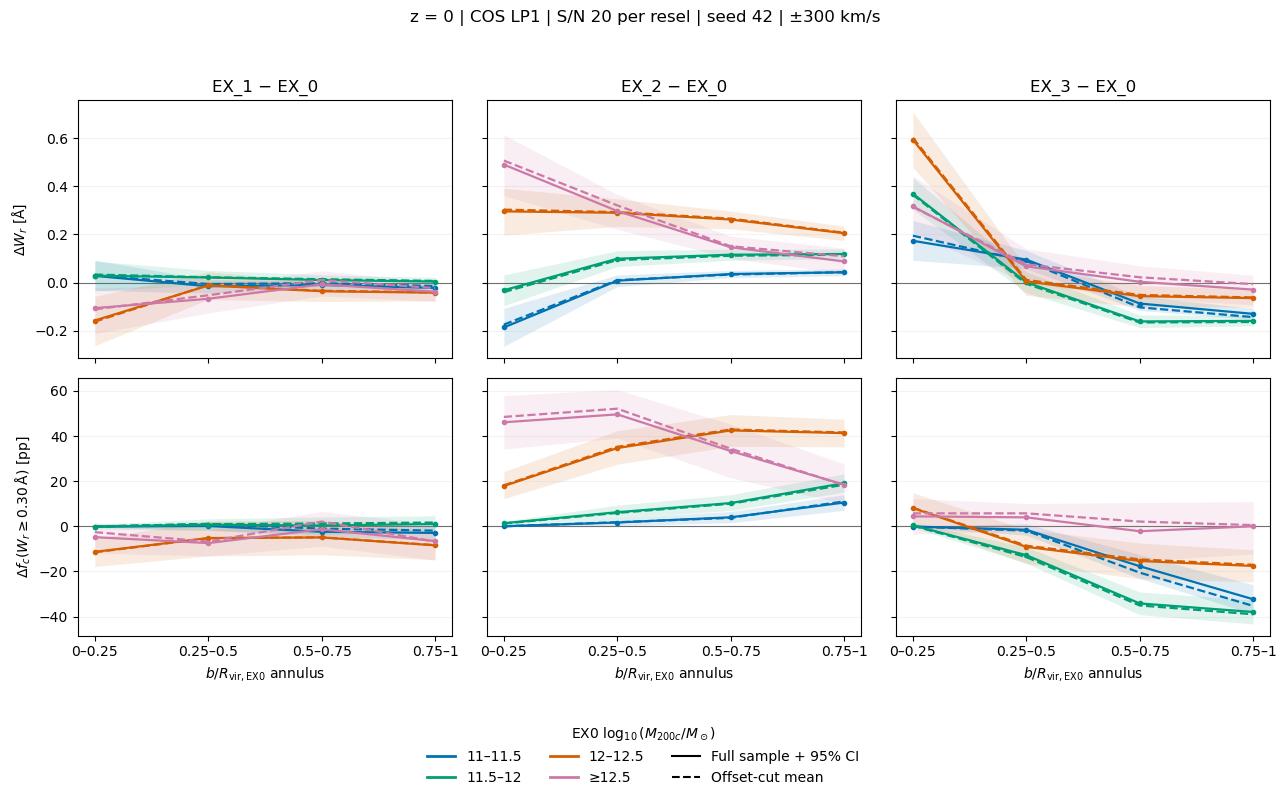

In [100]:
mass_order = ["11-11.5", "11.5-12", "12-12.5", ">=12.5"]
mass_rng = np.random.default_rng(42)
MASS_NBOOT = 5000

mass_rows = []
mass_support_rows = []

for cohort, delta in [
    ("full", full_delta_by_halo),
    ("offset_cut", offset_delta_by_halo),
]:
    meta = full_meta.loc[delta.index]

    for mass_bin in mass_order:
        ids = meta.index[meta["mass_bin"].eq(mass_bin)]
        x = delta.loc[ids].to_numpy(dtype=float)
        n = len(ids)

        # Whole-halo draws shared across models, radii and all other columns.
        counts = mass_rng.multinomial(
            n, np.full(n, 1.0 / n), size=MASS_NBOOT
        )
        boot = (counts @ x) / n

        result = delta.columns.to_frame(index=False)
        result["cohort"] = cohort
        result["mass_bin"] = mass_bin
        result["n_halos"] = n
        result["mean_delta"] = x.mean(axis=0)
        result["ci_low"], result["ci_high"] = np.quantile(
            boot, [0.025, 0.975], axis=0
        )
        mass_rows.append(result)

        mass_support_rows.append({
            "cohort": cohort,
            "mass_bin": mass_bin,
            "n_halos": n,
            "low_sSFR": int(meta.loc[ids, "type_EX0"].eq("low_sSFR").sum()),
            "star-forming": int(
                meta.loc[ids, "type_EX0"].eq("star-forming").sum()
            ),
        })

mass_profile_ci = pd.concat(mass_rows, ignore_index=True)
mass_profile_support = pd.DataFrame(mass_support_rows)
del counts, boot

mass_profile_ci.to_csv(
    FULL_OUT_ROOT / "mass_profiles_z0.csv", index=False
)
mass_profile_support.to_csv(
    FULL_OUT_ROOT / "mass_profile_support_z0.csv", index=False
)

mass_settings = {
    "redshift": 0.0,
    "snapshot": 90,
    "measurement_settings": "measurement_settings_z0.json",
    "offset_cohort": "center_offset_cohort_z0.csv",
    "primary_cohort": "full",
    "sensitivity_cohort": "offset_cut",
    "mass_definition": "EX0 log10(M200c/Msun)",
    "mass_bin_order": mass_order,
    "types": "Pooled within each mass bin.",
    "estimator": "Equal-weight halo mean of model minus EX0, per annulus.",
    "bootstrap_draws": MASS_NBOOT,
    "bootstrap_seed": 42,
    "bootstrap": "Whole halos within mass bin; paired across all columns.",
    "intervals": "Pointwise 95% percentile intervals, within one simulation box.",
    "noise_seeds": "Separate conditions.",
    "stored_units": {"W_r_A": "angstrom", "fc_010": "fraction", "fc_030": "fraction"},
}
(FULL_OUT_ROOT / "mass_profile_settings_z0.json").write_text(
    json.dumps(mass_settings, indent=2) + "\n", encoding="utf-8"
)

display(mass_profile_support)

# Plot the headline observing condition.
mass_headline = mass_profile_ci.loc[
    mass_profile_ci["condition"].eq("lp1_snr20")
    & mass_profile_ci["noise_seed"].eq(42)
    & mass_profile_ci["half_window_kms"].eq(300)
]

colors = ["#0072B2", "#009E73", "#D55E00", "#CC79A7"]
models = ["EX_1", "EX_2", "EX_3"]
metrics = [
    ("W_r_A", 1.0, r"$\Delta W_r$ [Å]"),
    ("fc_030", 100.0, r"$\Delta f_c(W_r \geq 0.30\,\mathrm{\AA})$ [pp]"),
]
xplot = np.arange(4)

fig, axes = plt.subplots(
    2, 3, figsize=(13, 8), sharex=True, sharey="row"
)

for j, model in enumerate(models):
    for i, (metric, scale, ylabel) in enumerate(metrics):
        ax = axes[i, j]

        for mass_bin, color in zip(mass_order, colors):
            for cohort, linestyle in [("full", "-"), ("offset_cut", "--")]:
                profile = (
                    mass_headline.loc[
                        mass_headline["model"].eq(model)
                        & mass_headline["metric"].eq(metric)
                        & mass_headline["mass_bin"].eq(mass_bin)
                        & mass_headline["cohort"].eq(cohort)
                    ]
                    .set_index("b_bin")
                    .reindex(range(4))
                )

                ax.plot(
                    xplot, scale * profile["mean_delta"].to_numpy(),
                    color=color, linestyle=linestyle, linewidth=1.6,
                    marker="o" if cohort == "full" else None,
                    markersize=3,
                )
                if cohort == "full":
                    ax.fill_between(
                        xplot,
                        scale * profile["ci_low"].to_numpy(),
                        scale * profile["ci_high"].to_numpy(),
                        color=color, alpha=0.12, linewidth=0,
                    )

        ax.axhline(0, color="0.4", linewidth=0.8, zorder=0)
        ax.grid(axis="y", alpha=0.15)
        if j == 0:
            ax.set_ylabel(ylabel)
        if i == 0:
            ax.set_title(f"{model} − EX_0")
        else:
            ax.set_xticks(xplot)
            ax.set_xticklabels(["0–0.25", "0.25–0.5", "0.5–0.75", "0.75–1"])
            ax.set_xlabel(r"$b/R_{\mathrm{vir,EX0}}$ annulus")

handles = [
    Line2D([0], [0], color=color, linewidth=2, label=label)
    for color, label in zip(
        colors, ["11–11.5", "11.5–12", "12–12.5", "≥12.5"]
    )
]
handles += [
    Line2D([0], [0], color="black", label="Full sample + 95% CI"),
    Line2D([0], [0], color="black", linestyle="--", label="Offset-cut mean"),
]
fig.legend(
    handles=handles, loc="lower center", ncol=3, frameon=False,
    title=r"EX0 $\log_{10}(M_{200c}/M_\odot)$",
)
fig.suptitle("z = 0 | COS LP1 | S/N 20 per resel | seed 42 | ±300 km/s")
fig.tight_layout(rect=[0, 0.12, 1, 0.95])

figure_path = FULL_OUT_ROOT / "mass_profiles_lp1_snr20_s42_v300_z0"
fig.savefig(figure_path.with_suffix(".png"), dpi=200, bbox_inches="tight")
fig.savefig(figure_path.with_suffix(".pdf"), bbox_inches="tight")
plt.show()

In [ ]:
forecast_models = ["EX_0", "EX_1", "EX_2", "EX_3"]

outer_grid = (
    full_halo.loc[
        full_halo["condition"].eq("lp1_snr20")
        & full_halo["noise_seed"].eq(42)
        & full_halo["half_window_kms"].eq(300)
        & full_halo["b_bin"].isin([2, 3])
    ]
    .pivot(
        index="group_id_EX0",
        columns=["model", "b_bin"],
        values="fc_030",
    )
    .reindex(full_delta_by_halo.index)
)

# Expected detection probability for one randomly placed outer sightline.
forecast_halo_p = pd.DataFrame({
    model: (
        5 * outer_grid[(model, 2)]
        + 7 * outer_grid[(model, 3)]
    ) / 12
    for model in forecast_models
})
forecast_halo_p = forecast_halo_p.join(
    offset_meta[["mass_bin", "type_EX0", "fine_mass_bin", "retained"]]
)

# Four mass-bin populations, pooling types within each bin.
forecast_specs = {
    f"mass_{mass_bin}": [
        (
            offset_meta.index[offset_meta["mass_bin"].eq(mass_bin)],
            1.0,
        )
    ]
    for mass_bin in mass_order
}

# Reuse the established 12.0–12.4 type selections and fixed mass weights.
forecast_specs.update({
    label: offset_specs[label]
    for label in ["std_low_sSFR", "std_star-forming"]
})

forecast_rows = []
for cohort, cohort_ids in [
    ("full", offset_analysis_ids),
    ("offset_cut", offset_keep_ids),
]:
    for selection, strata in forecast_specs.items():
        probabilities = pd.Series(0.0, index=forecast_models)
        n_halos = 0

        for original_ids, weight in strata:
            ids = original_ids[original_ids.isin(cohort_ids)]
            if len(ids) == 0:
                raise ValueError(f"Unsupported stratum: {cohort}, {selection}")

            probabilities += (
                weight * forecast_halo_p.loc[ids, forecast_models].mean()
            )
            n_halos += len(ids)

        forecast_rows.append({
            "cohort": cohort,
            "selection": selection,
            "n_sim_halos": n_halos,
            **probabilities.to_dict(),
        })

forecast_probabilities = pd.DataFrame(forecast_rows)

# Store probabilities as fractions.
forecast_halo_p.to_csv(
    FULL_OUT_ROOT / "forecast_outer_halo_probabilities_z0.csv",
    index_label="group_id_EX0",
)
forecast_probabilities.to_csv(
    FULL_OUT_ROOT / "forecast_outer_probabilities_z0.csv",
    index=False,
)

forecast_settings = {
    "redshift": 0.0,
    "snapshot": 90,
    "condition": "lp1_snr20",
    "noise_seed": 42,
    "half_window_kms": 300,
    "covering_threshold_A": 0.30,
    "b_over_Rvir_EX0_range": [0.5, 1.0],
    "annular_selection_probabilities": {"2": 5 / 12, "3": 7 / 12},
    "sightlines_per_observed_galaxy": 1,
    "mass_bins": mass_order,
    "standardized_type_mass_edges": [12.0, 12.1, 12.2, 12.3, 12.4],
    "standardized_type_mass_probabilities": offset_weights.tolist(),
    "halo_sampling": "Uniform within each selected mass/type stratum.",
    "planned_null": "EX_0",
    "planned_alternatives": ["EX_1", "EX_2", "EX_3"],
    "false_positive_probability_per_comparison": 0.05,
    "target_powers": [0.80, 0.95],
    "scope": (
        "Conditional on the simulated populations, EX0-defined selections "
        "and adopted observational model; independent observed galaxies."
    ),
}
_ = (FULL_OUT_ROOT / "forecast_outer_settings_z0.json").write_text(
    json.dumps(forecast_settings, indent=2) + "\n",
    encoding="utf-8",
)

probability_display = forecast_probabilities.set_index(["cohort", "selection"])
probability_display[forecast_models] *= 100
probability_display = probability_display.rename(
    columns={model: f"{model} [%]" for model in forecast_models}
)
display(probability_display.round(2))

n_sim_halos  EX_0 [%]  EX_1 [%]  EX_2 [%]  \
cohort     selection                                                     
full       mass_11-11.5               65     84.64     81.90     92.43   
           mass_11.5-12               99     81.90     82.62     97.32   
           mass_12-12.5               64     52.82     45.82     94.59   
           mass_>=12.5                19     31.80     27.41     56.43   
           std_low_sSFR               26     60.07     33.42     94.90   
           std_star-forming           29     48.68     58.56     96.88   
offset_cut mass_11-11.5               56     85.40     83.84     93.38   
           mass_11.5-12               96     82.70     84.17     97.60   
           mass_12-12.5               63     52.41     45.51     94.50   
           mass_>=12.5                16     30.86     27.78     55.82   
           std_low_sSFR               26     60.07     33.42     94.90   
           std_star-forming           28     48.12     58.37     96.80   

                             EX_3 [%]  
cohort     selection                   
full       mass_11-11.5         58.42  
           mass_11.5-12         45.51  
           mass_12-12.5         36.17  
           mass_>=12.5          30.88  
           std_low_sSFR         33.15  
           std_star-forming     39.13  
offset_cut mass_11-11.5         56.27  
           mass_11.5-12         45.36  
           mass_12-12.5         36.34  
           mass_>=12.5          32.03  
           std_low_sSFR         33.15  
           std_star-forming     39.70

In [102]:
from scipy.stats import binom

def binomial_count_test(n, p0, p1, alpha=0.05):
    """Return rejection cutoff, actual false-positive rate, and power."""
    n = np.atleast_1d(n).astype(int)

    if p1 < p0:
        # Reject for K <= k; choose the largest admissible cutoff.
        k = binom.ppf(alpha, n, p0).astype(int)
        k -= binom.cdf(k, n, p0) > alpha
        k += binom.cdf(k + 1, n, p0) <= alpha
        actual_alpha = binom.cdf(k, n, p0)
        power = binom.cdf(k, n, p1)
    else:
        # Reject for K >= k; choose the smallest admissible cutoff.
        k = binom.isf(alpha, n, p0).astype(int) + 1
        k -= binom.sf(k - 2, n, p0) <= alpha
        k += binom.sf(k - 1, n, p0) > alpha
        actual_alpha = binom.sf(k - 1, n, p0)
        power = binom.sf(k - 1, n, p1)

    return k, actual_alpha, power


def exact_pair_counts(
    p0, p1, alpha=0.05, targets=(0.80, 0.95),
    max_pairs=100_000, batch_size=2048,
):
    """Find the first integer N attaining each requested power."""
    found = {}

    if p1 != p0:
        # Search every integer: discrete-test power need not be monotonic.
        for start in range(1, max_pairs + 1, batch_size):
            n = np.arange(start, min(start + batch_size, max_pairs + 1))
            cutoff, actual_alpha, power = binomial_count_test(
                n, p0, p1, alpha
            )

            for target in targets:
                if target in found:
                    continue

                hit = np.flatnonzero(power >= target)
                if hit.size:
                    j = int(hit[0])
                    k = int(cutoff[j])
                    found[target] = {
                        "target_power": target,
                        "N_pairs": int(n[j]),
                        "critical_count": k,
                        "reject_rule": f"K {'<=' if p1 < p0 else '>='} {k}",
                        "actual_alpha": float(actual_alpha[j]),
                        "achieved_power": float(power[j]),
                        "status": "reached",
                    }

            if len(found) == len(targets):
                break

    return [
        found.get(target, {
            "target_power": target,
            "N_pairs": None,
            "critical_count": None,
            "reject_rule": None,
            "actual_alpha": None,
            "achieved_power": None,
            "status": "same_probability" if p1 == p0 else "not_reached",
        })
        for target in targets
    ]


FORECAST_CAP = 100_000
forecast_exact_rows = []

for _, population in forecast_probabilities.iterrows():
    p0 = float(population["EX_0"])

    for model in forecast_models[1:]:
        p1 = float(population[model])

        for result in exact_pair_counts(p0, p1, max_pairs=FORECAST_CAP):
            forecast_exact_rows.append({
                "cohort": population["cohort"],
                "selection": population["selection"],
                "model": model,
                "n_sim_halos": int(population["n_sim_halos"]),
                "p0": p0,
                "p1": p1,
                "alpha_requested": 0.05,
                **result,
            })

forecast_exact = pd.DataFrame(forecast_exact_rows).astype({
    "N_pairs": "Int64",
    "critical_count": "Int64",
})
forecast_exact.to_csv(
    FULL_OUT_ROOT / "forecast_outer_exact_binomial_z0.csv",
    index=False,
)

forecast_settings.update({
    "test_method": (
        "One-sided exact binomial count test; direction fixed by p1-p0."
    ),
    "maximum_pairs_searched": FORECAST_CAP,
    "N_definition": (
        "Smallest integer N attaining the requested power at that N."
    ),
    "probability_treatment": (
        "Unrounded empirical probabilities held fixed; "
        "finite-halo uncertainty not yet propagated."
    ),
})
_ = (FULL_OUT_ROOT / "forecast_outer_settings_z0.json").write_text(
    json.dumps(forecast_settings, indent=2) + "\n",
    encoding="utf-8",
)

count_display = (
    forecast_exact.assign(
        case=(
            forecast_exact["model"]
            + "_N"
            + (100 * forecast_exact["target_power"])
              .round().astype(int).astype(str)
        )
    )
    .pivot(
        index=["cohort", "selection"],
        columns="case",
        values="N_pairs",
    )
    .astype("Int64")
    .astype("string")
    .fillna(f">{FORECAST_CAP}")
)
count_display.columns.name = None
display(count_display.reset_index())

,cohort,selection,EX_1_N80,EX_1_N95,EX_2_N80,EX_2_N95,EX_3_N80,EX_3_N95
0,full,mass_11-11.5,1147,2027,107,177,18,32
1,full,mass_11.5-12,16995,29680,25,41,11,19
2,full,mass_12-12.5,325,561,8,11,59,98
3,full,mass_>=12.5,674,1182,24,47,15967,27915
4,full,std_low_sSFR,25,40,10,14,25,38
5,full,std_star-forming,162,275,5,8,169,293
6,offset_cut,mass_11-11.5,3282,5770,96,163,14,27
7,offset_cut,mass_11.5-12,3993,6939,26,43,11,19
8,offset_cut,mass_12-12.5,325,571,8,11,61,105
9,offset_cut,mass_>=12.5,1366,2367,27,43,9707,17007


In [103]:
FORECAST_BOOT_DRAWS = 5000
FORECAST_BOOT_CAP = 10_000
forecast_boot_rng = np.random.default_rng(42)

forecast_boot_cases = [
    ("mass_12-12.5", "EX_2"),
    ("mass_11.5-12", "EX_3"),
    ("std_star-forming", "EX_2"),
    ("std_low_sSFR", "EX_1"),
]

nominal_rates = (
    forecast_probabilities.loc[forecast_probabilities["cohort"].eq("full")]
    .set_index("selection")
)
nominal_n95 = (
    forecast_exact.loc[
        forecast_exact["cohort"].eq("full")
        & forecast_exact["target_power"].eq(0.95)
    ]
    .set_index(["selection", "model"])["N_pairs"]
)

# Resample whole halos, preserving model pairing and fixed stratum weights.
forecast_p_boot = {}
for selection in dict.fromkeys(s for s, m in forecast_boot_cases):
    probabilities = np.zeros((FORECAST_BOOT_DRAWS, len(forecast_models)))

    for ids, weight in forecast_specs[selection]:
        x = forecast_halo_p.loc[ids, forecast_models].to_numpy(dtype=float)
        n = len(ids)
        counts = forecast_boot_rng.multinomial(
            n, np.full(n, 1.0 / n), size=FORECAST_BOOT_DRAWS
        )
        probabilities += weight * (counts @ x) / n

    # Protect probability bounds against floating-point roundoff.
    forecast_p_boot[selection] = np.clip(probabilities, 0.0, 1.0)

forecast_boot_tables = []
forecast_uncertainty_rows = []
quantile_positions = (
    np.ceil(np.array([0.025, 0.50, 0.975]) * FORECAST_BOOT_DRAWS)
    .astype(int) - 1
)

for selection, model in forecast_boot_cases:
    print(f"Calculating repeat forecasts: {selection}, {model}", flush=True)

    probabilities = forecast_p_boot[selection]
    p0_draws = probabilities[:, forecast_models.index("EX_0")]
    p1_draws = probabilities[:, forecast_models.index(model)]

    original_direction = np.sign(
        nominal_rates.loc[selection, model]
        - nominal_rates.loc[selection, "EX_0"]
    )

    n95_draws = np.full(FORECAST_BOOT_DRAWS, np.inf)
    status = np.full(FORECAST_BOOT_DRAWS, "above_cap", dtype=object)

    for b, (p0, p1) in enumerate(zip(p0_draws, p1_draws)):
        # Keep the original predicted direction; do not silently reverse it.
        if original_direction * (p1 - p0) <= 0:
            status[b] = "reversed_or_zero"
            continue

        result = exact_pair_counts(
            p0, p1,
            targets=(0.95,),
            max_pairs=FORECAST_BOOT_CAP,
            batch_size=64,
        )[0]

        if result["N_pairs"] is not None:
            n95_draws[b] = result["N_pairs"]
            status[b] = "reached"

    # Include unresolved repeats when locating the percentile endpoints.
    lo, median, hi = np.sort(n95_draws)[quantile_positions]

    forecast_uncertainty_rows.append({
        "selection": selection,
        "model": model,
        "original_N95": int(nominal_n95.loc[(selection, model)]),
        "resampled_median_N95": median,
        "N95_lo": lo,
        "N95_hi": hi,
        "reversed_or_zero_pct": 100 * np.mean(status == "reversed_or_zero"),
        "above_cap_pct": 100 * np.mean(status == "above_cap"),
    })

    draws = pd.DataFrame({
        "cohort": "full",
        "selection": selection,
        "model": model,
        "bootstrap_id": np.arange(FORECAST_BOOT_DRAWS),
        "p0": p0_draws,
        "p1": p1_draws,
        "N95": np.where(np.isfinite(n95_draws), n95_draws, np.nan),
        "status": status,
    })
    draws["N95"] = draws["N95"].astype("Int64")
    forecast_boot_tables.append(draws)

forecast_n95_uncertainty = pd.DataFrame(forecast_uncertainty_rows)
forecast_n95_uncertainty.to_csv(
    FULL_OUT_ROOT / "forecast_outer_n95_uncertainty_z0.csv", index=False
)
pd.concat(forecast_boot_tables, ignore_index=True).to_csv(
    FULL_OUT_ROOT / "forecast_outer_n95_bootstrap_z0.csv.gz", index=False
)

forecast_settings["halo_resampling"] = {
    "cohort": "full",
    "draws": FORECAST_BOOT_DRAWS,
    "seed": 42,
    "cases": [
        {"selection": selection, "model": model}
        for selection, model in forecast_boot_cases
    ],
    "max_pairs_per_repeat": FORECAST_BOOT_CAP,
    "mass_weights": "Fixed to the original selection weights.",
    "model_pairing": "Identical halo draws across all models.",
    "test_direction": "Fixed to the original predicted direction.",
    "rejection_cutoff": "Recomputed from resampled EX0 probability each repeat.",
    "reported_range": "Central 95% of repeat N95 estimates.",
    "unresolved_repeats": "Retained in percentile ordering above the search cap.",
}
_ = (FULL_OUT_ROOT / "forecast_outer_settings_z0.json").write_text(
    json.dumps(forecast_settings, indent=2) + "\n", encoding="utf-8"
)

uncertainty_display = forecast_n95_uncertainty.copy()
for column in [
    "original_N95", "resampled_median_N95", "N95_lo", "N95_hi"
]:
    uncertainty_display[column] = uncertainty_display[column].map(
        lambda value: (
            f"{int(value):,}" if np.isfinite(value)
            else f">{FORECAST_BOOT_CAP:,}"
        )
    )
display(uncertainty_display.round(2))

Calculating repeat forecasts: mass_12-12.5, EX_2
Calculating repeat forecasts: mass_11.5-12, EX_3
Calculating repeat forecasts: std_star-forming, EX_2
Calculating repeat forecasts: std_low_sSFR, EX_1


,selection,model,original_N95,resampled_median_N95,N95_lo,N95_hi,reversed_or_zero_pct,above_cap_pct
0,mass_12-12.5,EX_2,11,11,8,14,0.0,0.0
1,mass_11.5-12,EX_3,19,19,14,26,0.0,0.0
2,std_star-forming,EX_2,8,8,6,10,0.0,0.0
3,std_low_sSFR,EX_1,40,39,22,86,0.0,0.0


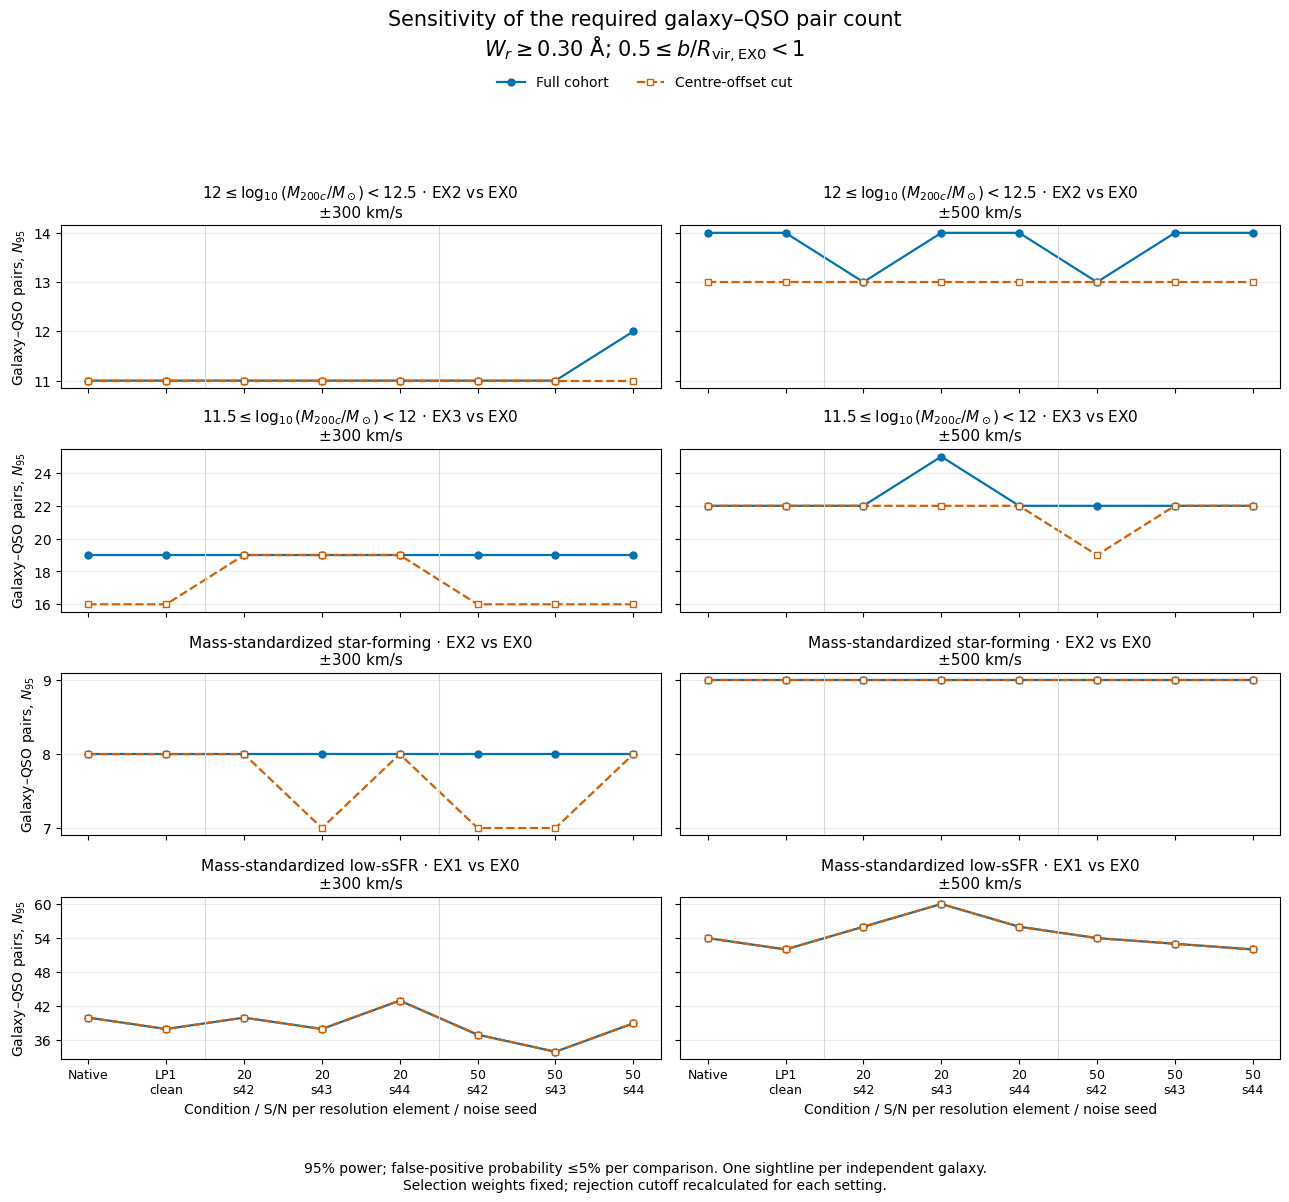

N95_min  N95_max
selection        model cohort                      
mass_12-12.5     EX_2  full             11       14
                       offset_cut       11       13
mass_11.5-12     EX_3  full             19       25
                       offset_cut       16       22
std_star-forming EX_2  full              8        9
                       offset_cut        7        9
std_low_sSFR     EX_1  full             34       60
                       offset_cut       34       60

In [105]:
import matplotlib.pyplot as plt
from matplotlib.ticker import MaxNLocator

sensitivity_settings = [
    ("native", -1),
    ("lp1_clean", -1),
    ("lp1_snr20", 42),
    ("lp1_snr20", 43),
    ("lp1_snr20", 44),
    ("lp1_snr50", 42),
    ("lp1_snr50", 43),
    ("lp1_snr50", 44),
]
sensitivity_labels = [
    "Native", "LP1\nclean",
    "20\ns42", "20\ns43", "20\ns44",
    "50\ns42", "50\ns43", "50\ns44",
]
sensitivity_cases = [
    ("mass_12-12.5", "EX_2"),
    ("mass_11.5-12", "EX_3"),
    ("std_star-forming", "EX_2"),
    ("std_low_sSFR", "EX_1"),
]
selection_labels = {
    "mass_12-12.5": r"$12 \leq \log_{10}(M_{200c}/M_\odot) < 12.5$",
    "mass_11.5-12": r"$11.5 \leq \log_{10}(M_{200c}/M_\odot) < 12$",
    "std_star-forming": "Mass-standardized star-forming",
    "std_low_sSFR": "Mass-standardized low-sSFR",
}

SENSITIVITY_CAP = 100_000
reference_rates = forecast_probabilities.loc[
    forecast_probabilities["cohort"].eq("full")
].set_index("selection")

outer_measurements = full_halo.loc[full_halo["b_bin"].isin([2, 3])]
sensitivity_rows = []

for condition, noise_seed in sensitivity_settings:
    for window in (300, 500):
        selected = outer_measurements.loc[
            outer_measurements["condition"].eq(condition)
            & outer_measurements["noise_seed"].eq(noise_seed)
            & outer_measurements["half_window_kms"].eq(window)
        ]
        grid = selected.pivot(
            index="group_id_EX0",
            columns=["model", "b_bin"],
            values="fc_030",
        ).reindex(full_delta_by_halo.index)

        # One sightline drawn uniformly in projected area over 0.5–1 Rvir.
        outer_p = pd.DataFrame({
            model: (5 * grid[(model, 2)] + 7 * grid[(model, 3)]) / 12
            for model in forecast_models
        })
        assert np.isfinite(outer_p.to_numpy()).all(), (
            condition, noise_seed, window
        )

        for selection, model in sensitivity_cases:
            reference_direction = np.sign(
                reference_rates.loc[selection, model]
                - reference_rates.loc[selection, "EX_0"]
            )

            for cohort in ("full", "offset_cut"):
                probabilities = pd.Series(0.0, index=forecast_models)
                n_halos = 0

                for original_ids, weight in forecast_specs[selection]:
                    ids = pd.Index(original_ids)
                    if cohort == "offset_cut":
                        ids = ids.intersection(offset_keep_ids)
                    if len(ids) == 0:
                        raise ValueError(
                            f"Unsupported stratum: {selection}, {cohort}"
                        )
                    probabilities += weight * outer_p.loc[ids].mean()
                    n_halos += len(ids)

                p0 = float(probabilities["EX_0"])
                p1 = float(probabilities[model])

                # Preserve the direction chosen in the original forecast.
                if reference_direction * (p1 - p0) <= 0:
                    result = {
                        "target_power": 0.95,
                        "N_pairs": None,
                        "status": "reversed_or_zero",
                    }
                else:
                    result = exact_pair_counts(
                        p0, p1, alpha=0.05, targets=(0.95,),
                        max_pairs=SENSITIVITY_CAP, batch_size=64,
                    )[0]

                sensitivity_rows.append({
                    "cohort": cohort,
                    "selection": selection,
                    "model": model,
                    "condition": condition,
                    "noise_seed": noise_seed,
                    "half_window_kms": window,
                    "n_sim_halos": n_halos,
                    "p0": p0,
                    "p1": p1,
                    "alpha_requested": 0.05,
                    **result,
                })

forecast_sensitivity = pd.DataFrame(sensitivity_rows)
forecast_sensitivity["N_pairs"] = (
    forecast_sensitivity["N_pairs"].astype("Int64")
)
forecast_sensitivity.to_csv(
    FULL_OUT_ROOT / "forecast_outer_sensitivity_z0.csv", index=False
)

forecast_settings["measurement_sensitivity"] = {
    "cases": [
        {"selection": selection, "model": model}
        for selection, model in sensitivity_cases
    ],
    "cohorts": ["full", "offset_cut"],
    "settings": [
        {"condition": condition, "noise_seed": seed}
        for condition, seed in sensitivity_settings
    ],
    "half_windows_kms": [300, 500],
    "target_power": 0.95,
    "maximum_pairs_searched": SENSITIVITY_CAP,
    "test_direction": "Fixed to full-cohort SNR20, seed42, +/-300 prediction.",
    "rejection_cutoff": "Recomputed from each setting's EX0 probability.",
    "halo_resampling": "None in this sensitivity calculation.",
}
(FULL_OUT_ROOT / "forecast_outer_settings_z0.json").write_text(
    json.dumps(forecast_settings, indent=2) + "\n"
)

unresolved = forecast_sensitivity.loc[
    forecast_sensitivity["status"].ne("reached")
]
if not unresolved.empty:
    display(unresolved)
    raise RuntimeError(
        "Some forecasts reversed direction or exceeded the search cap. "
        "Inspect these rows before plotting."
    )

# Four selections × two velocity windows.
fig, axes = plt.subplots(
    4, 2, figsize=(13, 12), sharex=True, sharey="row"
)
setting_index = pd.MultiIndex.from_tuples(
    sensitivity_settings, names=["condition", "noise_seed"]
)
x = np.arange(len(sensitivity_settings))

for row, (selection, model) in enumerate(sensitivity_cases):
    for col, window in enumerate((300, 500)):
        ax = axes[row, col]

        for cohort, color, linestyle, marker, label in [
            ("full", "#0072B2", "-", "o", "Full cohort"),
            ("offset_cut", "#D55E00", "--", "s", "Centre-offset cut"),
        ]:
            curve = forecast_sensitivity.loc[
                forecast_sensitivity["selection"].eq(selection)
                & forecast_sensitivity["model"].eq(model)
                & forecast_sensitivity["cohort"].eq(cohort)
                & forecast_sensitivity["half_window_kms"].eq(window)
            ].set_index(["condition", "noise_seed"]).reindex(setting_index)

            ax.plot(
                x, curve["N_pairs"].to_numpy(dtype=float),
                color=color, linestyle=linestyle, marker=marker,
                markerfacecolor="white" if cohort == "offset_cut" else color,
                linewidth=1.6, markersize=5, label=label,
            )

        ax.set_title(
            f"{selection_labels[selection]} · {model.replace('_', '')} vs EX0\n"
            f"±{window} km/s",
            fontsize=11,
        )
        #ax.set_ylim(bottom=0)
        ax.yaxis.set_major_locator(MaxNLocator(nbins=5, integer=True))
        ax.set_xticks(x)
        ax.set_xticklabels(sensitivity_labels, fontsize=9)
        ax.grid(axis="y", alpha=0.25)
        ax.axvline(1.5, color="0.85", linewidth=0.8)
        ax.axvline(4.5, color="0.85", linewidth=0.8)

        if col == 0:
            ax.set_ylabel(r"Galaxy–QSO pairs, $N_{95}$")
        if row == 3:
            ax.set_xlabel("Condition / S/N per resolution element / noise seed")

fig.suptitle(
    "Sensitivity of the required galaxy–QSO pair count\n"
    r"$W_r \geq 0.30$ Å; $0.5 \leq b/R_{\rm vir,EX0} < 1$",
    fontsize=15, y=0.995,
)
handles, labels = axes[0, 0].get_legend_handles_labels()
fig.legend(
    handles, labels, loc="upper center",
    bbox_to_anchor=(0.5, 0.95), ncol=2, frameon=False,
)
fig.text(
    0.5, 0.012,
    "95% power; false-positive probability ≤5% per comparison. "
    "One sightline per independent galaxy.\n"
    "Selection weights fixed; rejection cutoff recalculated for each setting.",
    ha="center", fontsize=10,
)
fig.tight_layout(rect=(0, 0.06, 1, 0.92))

for extension in ("png", "pdf"):
    fig.savefig(
        FULL_OUT_ROOT / f"forecast_outer_sensitivity_z0.{extension}",
        dpi=200, bbox_inches="tight",
    )
plt.show()

forecast_sensitivity_range = (
    forecast_sensitivity
    .groupby(["selection", "model", "cohort"], sort=False)["N_pairs"]
    .agg(N95_min="min", N95_max="max")
)
display(forecast_sensitivity_range)

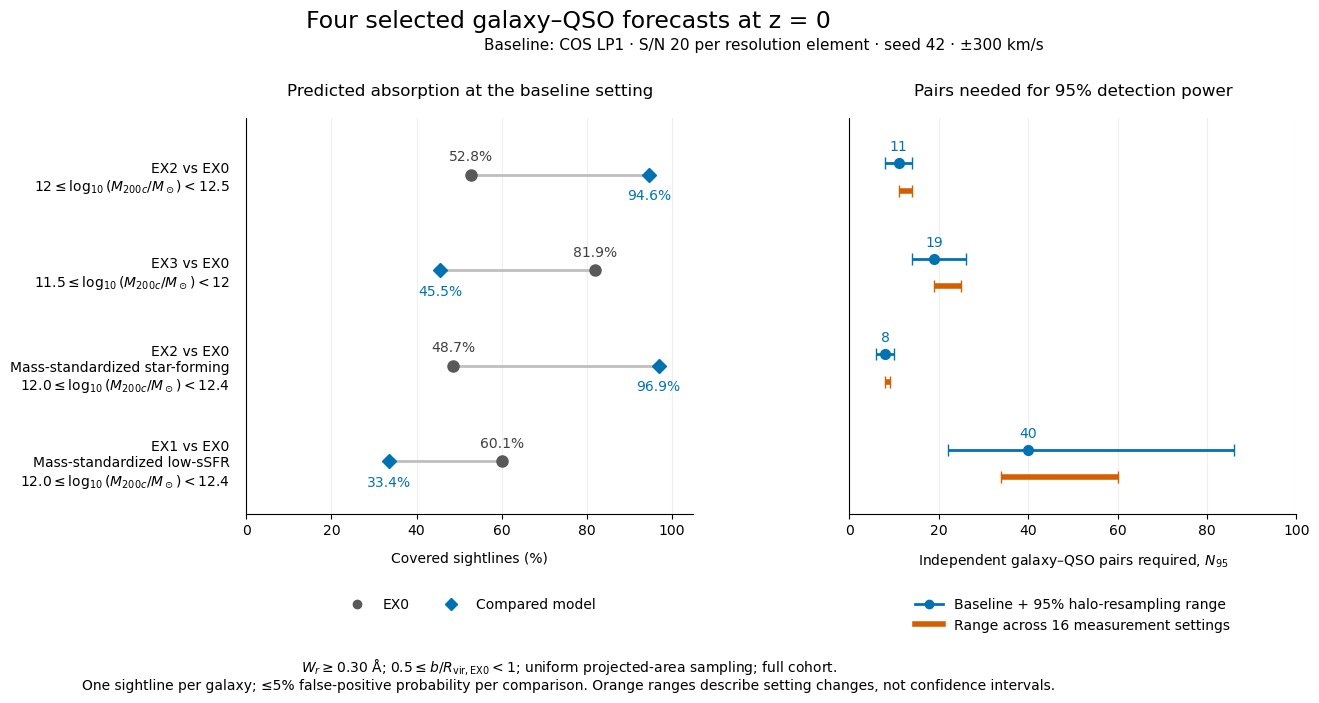

1006

In [106]:
from matplotlib.lines import Line2D

uncertainty_lookup = forecast_n95_uncertainty.set_index(
    ["selection", "model"]
)

summary_rows = []
row_labels = []

for selection, model in sensitivity_cases:
    rates = reference_rates.loc[selection]
    uncertainty = uncertainty_lookup.loc[(selection, model)]
    setting_range = forecast_sensitivity_range.loc[
        (selection, model, "full")
    ]

    summary_rows.append({
        "selection": selection,
        "model": model,
        "n_sim_halos": int(rates["n_sim_halos"]),
        "p0": float(rates["EX_0"]),
        "p1": float(rates[model]),
        "original_N95": int(uncertainty["original_N95"]),
        "bootstrap_lo": float(uncertainty["N95_lo"]),
        "bootstrap_hi": float(uncertainty["N95_hi"]),
        "settings_min": int(setting_range["N95_min"]),
        "settings_max": int(setting_range["N95_max"]),
    })

    population_label = selection_labels[selection]
    if selection.startswith("std_"):
        population_label += (
            "\n" + r"$12.0 \leq \log_{10}(M_{200c}/M_\odot) < 12.4$"
        )
    row_labels.append(
        f"{model.replace('_', '')} vs EX0\n{population_label}"
    )

forecast_summary = pd.DataFrame(summary_rows)
forecast_summary.to_csv(
    FULL_OUT_ROOT / "forecast_outer_summary_z0.csv", index=False
)

blue = "#0072B2"
orange = "#D55E00"
y_positions = np.arange(len(forecast_summary))[::-1]

fig, axes = plt.subplots(1, 2, figsize=(15, 7.2), sharey=True)

for i, row in forecast_summary.iterrows():
    y = y_positions[i]
    p0, p1 = 100 * row["p0"], 100 * row["p1"]

    # Left: baseline covering fractions.
    axes[0].plot([p0, p1], [y, y], color="0.75", linewidth=2)
    axes[0].plot(p0, y, "o", color="0.35", markersize=8)
    axes[0].plot(p1, y, "D", color=blue, markersize=7)

    axes[0].annotate(
        f"{p0:.1f}%", (p0, y), xytext=(0, 10),
        textcoords="offset points", ha="center", color="0.25",
    )
    axes[0].annotate(
        f"{p1:.1f}%", (p1, y), xytext=(0, -18),
        textcoords="offset points", ha="center", color=blue,
    )

    # Right, upper track: original N95 and halo-resampling range.
    n95 = row["original_N95"]
    axes[1].errorbar(
        n95, y + 0.12,
        xerr=np.array([
            [n95 - row["bootstrap_lo"]],
            [row["bootstrap_hi"] - n95],
        ]),
        fmt="o", color=blue, markersize=7,
        linewidth=2, capsize=4,
    )
    axes[1].annotate(
        f"{int(n95)}", (n95, y + 0.12), xytext=(0, 9),
        textcoords="offset points", ha="center", color=blue,
    )

    # Right, lower track: variation across the 16 measurement settings.
    axes[1].hlines(
        y - 0.17, row["settings_min"], row["settings_max"],
        color=orange, linewidth=4,
    )
    axes[1].plot(
        [row["settings_min"], row["settings_max"]],
        [y - 0.17, y - 0.17],
        linestyle="none", marker="|", color=orange, markersize=9,
    )

axes[0].set_yticks(y_positions)
axes[0].set_yticklabels(row_labels, fontsize=10)
axes[0].tick_params(axis="y", length=0, pad=12)
axes[1].tick_params(axis="y", labelleft=False, length=0)

axes[0].set_xlim(0, 105)
axes[0].set_xticks(np.arange(0, 101, 20))
axes[0].set_xlabel("Covered sightlines (%)", labelpad=10)
axes[0].set_title("Predicted absorption at the baseline setting", pad=16)

right_limit = max(
    100,
    20 * np.ceil(
        forecast_summary[["bootstrap_hi", "settings_max"]]
        .to_numpy().max() / 20
    ),
)
axes[1].set_xlim(0, right_limit)
axes[1].xaxis.set_major_locator(MaxNLocator(nbins=5, integer=True))
axes[1].set_xlabel(
    r"Independent galaxy–QSO pairs required, $N_{95}$", labelpad=10
)
axes[1].set_title("Pairs needed for 95% detection power", pad=16)

for ax in axes:
    ax.set_ylim(-0.55, len(forecast_summary) - 0.4)
    ax.grid(axis="x", alpha=0.2)
    ax.set_axisbelow(True)
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)

axes[0].legend(
    handles=[
        Line2D([], [], marker="o", linestyle="none", color="0.35",
               label="EX0"),
        Line2D([], [], marker="D", linestyle="none", color=blue,
               label="Compared model"),
    ],
    loc="upper center", bbox_to_anchor=(0.5, -0.18),
    ncol=2, frameon=False,
)
axes[1].legend(
    handles=[
        Line2D([], [], marker="o", color=blue, linewidth=2,
               label="Baseline + 95% halo-resampling range"),
        Line2D([], [], color=orange, linewidth=4,
               label="Range across 16 measurement settings"),
    ],
    loc="upper center", bbox_to_anchor=(0.5, -0.18),
    frameon=False,
)

fig.suptitle("Four selected galaxy–QSO forecasts at z = 0", fontsize=17, y=0.98)
fig.text(
    0.63, 0.925,
    "Baseline: COS LP1 · S/N 20 per resolution element · seed 42 · ±300 km/s",
    ha="center", fontsize=11,
)
fig.text(
    0.5, 0.035,
    r"$W_r \geq 0.30$ Å; $0.5 \leq b/R_{\rm vir,EX0} < 1$; "
    "uniform projected-area sampling; full cohort.\n"
    "One sightline per galaxy; ≤5% false-positive probability per comparison. "
    "Orange ranges describe setting changes, not confidence intervals.",
    ha="center", fontsize=10,
)
fig.subplots_adjust(
    left=0.285, right=0.985, bottom=0.28, top=0.83, wspace=0.35
)

for extension in ("png", "pdf"):
    fig.savefig(
        FULL_OUT_ROOT / f"forecast_outer_summary_z0.{extension}",
        dpi=200, bbox_inches="tight",
    )
plt.show()

forecast_summary_caption = (
    "Selected z=0 galaxy–QSO forecasts using the full matched cohort. "
    "Left: baseline covering fractions for EX0 and each indicated alternative, "
    "using COS LP1, S/N20 per resolution element, noise seed42, and a "
    "+/-300 km/s window. Sightlines are sampled uniformly in projected area "
    "over 0.5 <= b/Rvir_EX0 < 1, with Wr >= 0.30 Angstrom defining coverage. "
    "Both standardized type populations use the fixed pooled mass weights "
    "over log10(M200c/Msun)=12.0–12.4. "
    "Right: blue points give the original pair counts for 95% power; blue "
    "intervals contain the middle 95% of estimates from 5000 halo resamples. "
    "Orange intervals show the minimum and maximum across the 16 measurement "
    "settings and are not confidence intervals. The test direction remains "
    "fixed; rejection cutoffs are recalculated for each resampled or "
    "setting-specific EX0 rate. Forecasts assume independent galaxies, "
    "one sightline per galaxy, known continuum, and the adopted noise model. "
    "They do not include cosmic variance or observational selection errors."
)
(FULL_OUT_ROOT / "forecast_outer_summary_z0_caption.txt").write_text(
    forecast_summary_caption + "\n"
)

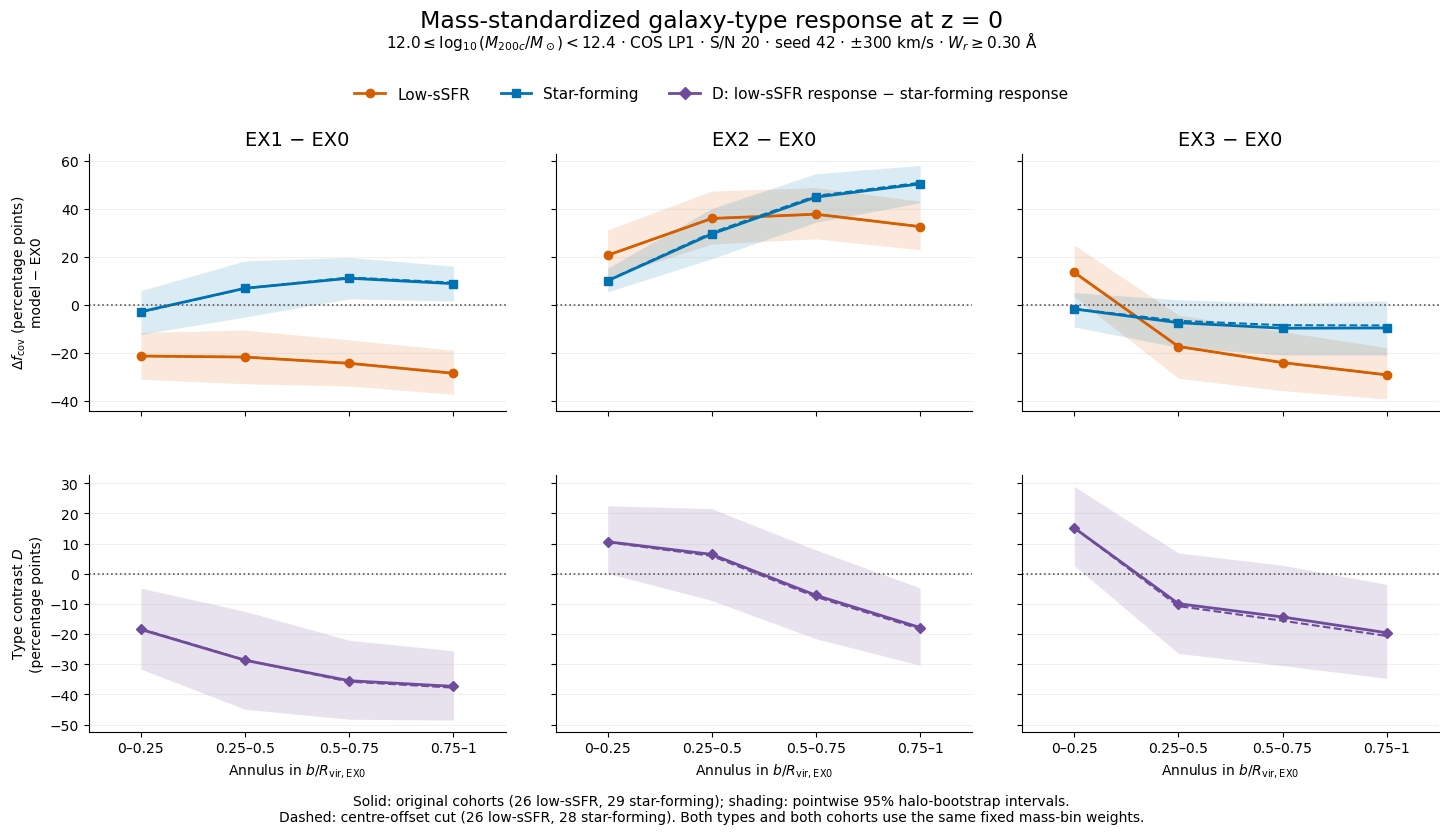

1048

In [107]:
from matplotlib.lines import Line2D

def select_type_figure_rows(frame):
    return frame.loc[
        frame["metric"].eq("fc_030")
        & frame["condition"].eq("lp1_snr20")
        & frame["noise_seed"].eq(42)
        & frame["half_window_kms"].eq(300)
    ].copy()

type_figure_data = select_type_figure_rows(mass_std_type_ci)
contrast_figure_data = select_type_figure_rows(mass_std_contrast_ci)
cut_figure_data = select_type_figure_rows(offset_sensitivity_ci)

type_styles = {
    "low_sSFR": ("#D55E00", "o", "Low-sSFR"),
    "star-forming": ("#0072B2", "s", "Star-forming"),
}
contrast_color = "#6F4C9B"

b_centres = np.array([0.125, 0.375, 0.625, 0.875])
b_labels = ["0–0.25", "0.25–0.5", "0.5–0.75", "0.75–1"]

fig, axes = plt.subplots(
    2, 3, figsize=(15, 8.5), sharex=True, sharey="row"
)

for col, model in enumerate(["EX_1", "EX_2", "EX_3"]):
    top, bottom = axes[:, col]

    # Top row: response within each standardized galaxy type.
    for galaxy_type, (color, marker, label) in type_styles.items():
        original = type_figure_data.loc[
            type_figure_data["model"].eq(model)
            & type_figure_data["type_EX0"].eq(galaxy_type)
        ].set_index("b_bin").reindex(range(4))

        retained = cut_figure_data.loc[
            cut_figure_data["model"].eq(model)
            & cut_figure_data["summary"].eq(f"std_{galaxy_type}")
        ].set_index("b_bin").reindex(range(4))

        top.fill_between(
            b_centres,
            100 * original["ci_low"].to_numpy(dtype=float),
            100 * original["ci_high"].to_numpy(dtype=float),
            color=color, alpha=0.14, linewidth=0,
        )
        top.plot(
            b_centres,
            100 * original["mean_delta"].to_numpy(dtype=float),
            color=color, marker=marker, linewidth=2, markersize=6,
        )
        top.plot(
            b_centres,
            100 * retained["mean_retained"].to_numpy(dtype=float),
            color=color, linestyle="--", linewidth=1.5,
        )

    # Bottom row: independently bootstrapped type contrast.
    original = contrast_figure_data.loc[
        contrast_figure_data["model"].eq(model)
    ].set_index("b_bin").reindex(range(4))

    retained = cut_figure_data.loc[
        cut_figure_data["model"].eq(model)
        & cut_figure_data["summary"].eq("std_type_contrast")
    ].set_index("b_bin").reindex(range(4))

    bottom.fill_between(
        b_centres,
        100 * original["ci_low"].to_numpy(dtype=float),
        100 * original["ci_high"].to_numpy(dtype=float),
        color=contrast_color, alpha=0.16, linewidth=0,
    )
    bottom.plot(
        b_centres,
        100 * original["mean_type_contrast"].to_numpy(dtype=float),
        color=contrast_color, marker="D", linewidth=2, markersize=5,
    )
    bottom.plot(
        b_centres,
        100 * retained["mean_retained"].to_numpy(dtype=float),
        color=contrast_color, linestyle="--", linewidth=1.5,
    )

    top.set_title(f"{model.replace('_', '')} − EX0", fontsize=14)
    bottom.set_xlabel(r"Annulus in $b/R_{\rm vir,EX0}$")

for ax in axes.flat:
    ax.axhline(0, color="0.35", linestyle=":", linewidth=1.2)
    ax.set_xlim(0, 1)
    ax.set_xticks(b_centres)
    ax.set_xticklabels(b_labels, fontsize=10)
    ax.grid(axis="y", alpha=0.18)
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)

axes[0, 0].set_ylabel(
    "$\\Delta f_{\\rm cov}$ (percentage points)\nmodel − EX0"
)
axes[1, 0].set_ylabel(
    "Type contrast $D$\n(percentage points)"
)

fig.suptitle(
    "Mass-standardized galaxy-type response at z = 0",
    fontsize=17, y=0.99,
)
fig.text(
    0.5, 0.945,
    r"$12.0 \leq \log_{10}(M_{200c}/M_\odot) < 12.4$"
    " · COS LP1 · S/N 20 · seed 42 · ±300 km/s"
    r" · $W_r \geq 0.30$ Å",
    ha="center", fontsize=11,
)
fig.legend(
    handles=[
        Line2D([], [], color="#D55E00", marker="o", linewidth=2,
               label="Low-sSFR"),
        Line2D([], [], color="#0072B2", marker="s", linewidth=2,
               label="Star-forming"),
        Line2D([], [], color=contrast_color, marker="D", linewidth=2,
               label="D: low-sSFR response − star-forming response"),
    ],
    loc="upper center", bbox_to_anchor=(0.5, 0.915),
    ncol=3, frameon=False, fontsize=11,
)
fig.text(
    0.5, 0.035,
    "Solid: original cohorts (26 low-sSFR, 29 star-forming); "
    "shading: pointwise 95% halo-bootstrap intervals.\n"
    "Dashed: centre-offset cut (26 low-sSFR, 28 star-forming). "
    "Both types and both cohorts use the same fixed mass-bin weights.",
    ha="center", fontsize=10,
)
fig.subplots_adjust(
    left=0.085, right=0.985, bottom=0.14, top=0.82,
    hspace=0.25, wspace=0.12,
)

type_figure_stem = (
    "mass_standardized_type_profiles_fc030_lp1_snr20_s42_v300_z0"
)
for extension in ("png", "pdf"):
    fig.savefig(
        FULL_OUT_ROOT / f"{type_figure_stem}.{extension}",
        dpi=200, bbox_inches="tight",
    )
plt.show()

type_figure_caption = (
    "Mass-standardized covering-fraction responses at z=0 for "
    "Wr >= 0.30 Angstrom, using the tabulated COS LP1 LSF, "
    "S/N20 per resolution element, noise seed42, and a +/-300 km/s window. "
    "Top: EX1/2/3 minus EX0 within each EX0-defined galaxy type. "
    "Bottom: the low-sSFR response minus the star-forming response. "
    "Points represent annular averages; connecting lines guide the eye. "
    "Types are standardized over log10(M200c/Msun)=12.0–12.4 using "
    "fixed weights (20,16,14,5)/55 in four 0.1-dex bins. "
    "Solid curves and shaded pointwise 95% intervals use the original "
    "26 low-sSFR and 29 star-forming halos. Intervals come from 5000 "
    "halo-bootstrap draws, resampling independently within type and mass "
    "strata while preserving model and radial pairing. "
    "Dashed curves show retained-cohort means after the common centre-offset "
    "cut, with 26 low-sSFR and 28 star-forming halos and unchanged weights. "
    "Mass standardization balances the binned mass distributions; "
    "it does not identify a causal effect of galaxy type. "
    "These single-box intervals do not include cosmic variance."
)
(FULL_OUT_ROOT / f"{type_figure_stem}_caption.txt").write_text(
    type_figure_caption + "\n"
)

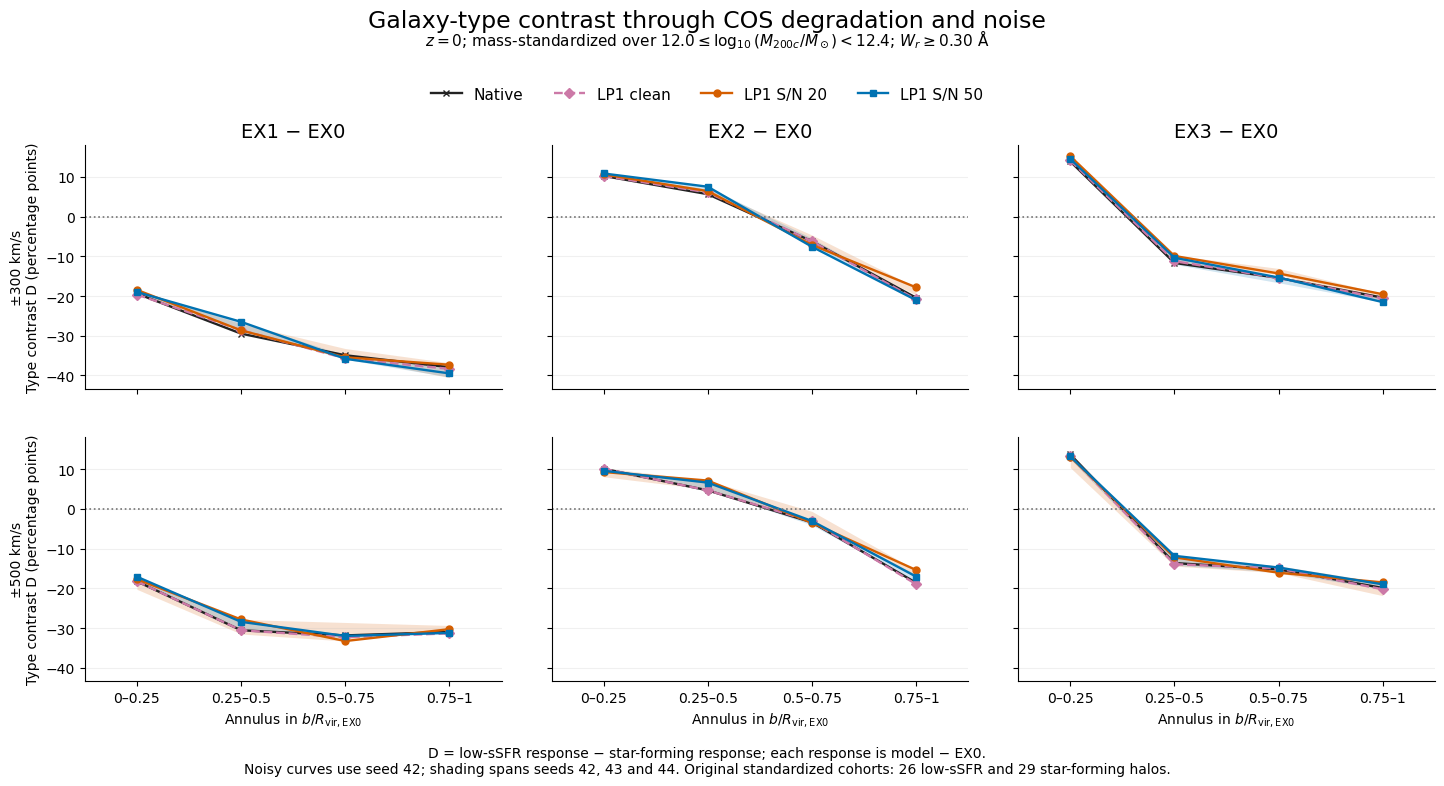

818

In [108]:
robustness_data = mass_std_contrast_ci.loc[
    mass_std_contrast_ci["metric"].eq("fc_030")
    & mass_std_contrast_ci["condition"].isin(
        ["native", "lp1_clean", "lp1_snr20", "lp1_snr50"]
    )
    & mass_std_contrast_ci["half_window_kms"].isin([300, 500])
].copy()

instrument_styles = {
    "native": ("#222222", "-", "x", "Native"),
    "lp1_clean": ("#CC79A7", "--", "D", "LP1 clean"),
    "lp1_snr20": ("#D55E00", "-", "o", "LP1 S/N 20"),
    "lp1_snr50": ("#0072B2", "-", "s", "LP1 S/N 50"),
}

fig, axes = plt.subplots(
    2, 3, figsize=(15, 8), sharex=True, sharey=True
)

for row, window in enumerate([300, 500]):
    for col, model in enumerate(["EX_1", "EX_2", "EX_3"]):
        ax = axes[row, col]
        panel = robustness_data.loc[
            robustness_data["model"].eq(model)
            & robustness_data["half_window_kms"].eq(window)
        ]

        for condition, (color, linestyle, marker, label) in (
            instrument_styles.items()
        ):
            condition_data = panel.loc[
                panel["condition"].eq(condition)
            ]

            if condition in ("native", "lp1_clean"):
                curve = (
                    condition_data.loc[condition_data["noise_seed"].eq(-1)]
                    .set_index("b_bin")
                    .loc[[0, 1, 2, 3], "mean_type_contrast"]
                )
            else:
                seed_values = condition_data.pivot(
                    index="b_bin",
                    columns="noise_seed",
                    values="mean_type_contrast",
                ).loc[[0, 1, 2, 3], [42, 43, 44]]

                ax.fill_between(
                    b_centres,
                    100 * seed_values.min(axis=1).to_numpy(dtype=float),
                    100 * seed_values.max(axis=1).to_numpy(dtype=float),
                    color=color, alpha=0.18, linewidth=0,
                )
                curve = seed_values[42]

            ax.plot(
                b_centres, 100 * curve.to_numpy(dtype=float),
                color=color, linestyle=linestyle, marker=marker,
                linewidth=1.7, markersize=5, label=label,
            )

        ax.axhline(0, color="0.45", linestyle=":", linewidth=1.2)
        ax.set_xlim(0, 1)
        ax.set_xticks(b_centres)
        ax.set_xticklabels(b_labels, fontsize=10)
        ax.grid(axis="y", alpha=0.18)
        ax.spines["top"].set_visible(False)
        ax.spines["right"].set_visible(False)

        if row == 0:
            ax.set_title(
                f"{model.replace('_', '')} − EX0", fontsize=14
            )
        if col == 0:
            ax.set_ylabel(
                f"±{window} km/s\nType contrast D (percentage points)"
            )
        if row == 1:
            ax.set_xlabel(r"Annulus in $b/R_{\rm vir,EX0}$")

fig.suptitle(
    "Galaxy-type contrast through COS degradation and noise",
    fontsize=17, y=0.99,
)
fig.text(
    0.5, 0.945,
    r"$z=0$; mass-standardized over "
    r"$12.0 \leq \log_{10}(M_{200c}/M_\odot) < 12.4$; "
    r"$W_r \geq 0.30$ Å",
    ha="center", fontsize=11,
)

handles, labels = axes[0, 0].get_legend_handles_labels()
fig.legend(
    handles, labels, loc="upper center",
    bbox_to_anchor=(0.5, 0.91), ncol=4, frameon=False, fontsize=11,
)

fig.text(
    0.5, 0.035,
    "D = low-sSFR response − star-forming response; "
    "each response is model − EX0.\n"
    "Noisy curves use seed 42; shading spans seeds 42, 43 and 44. "
    "Original standardized cohorts: 26 low-sSFR and 29 star-forming halos.",
    ha="center", fontsize=10,
)
fig.subplots_adjust(
    left=0.085, right=0.985, bottom=0.15, top=0.82,
    hspace=0.20, wspace=0.12,
)

robustness_stem = (
    "mass_standardized_type_contrast_instrument_sensitivity_fc030_z0"
)
for extension in ("png", "pdf"):
    fig.savefig(
        FULL_OUT_ROOT / f"{robustness_stem}.{extension}",
        dpi=200, bbox_inches="tight",
    )
plt.show()

robustness_caption = (
    "Sensitivity of the mass-standardized galaxy-type contrast in "
    "Wr >= 0.30 Angstrom covering fraction to COS degradation, noise, "
    "and velocity-window width at z=0. D is the low-sSFR mean response "
    "minus the star-forming mean response, with each response defined "
    "as EX1/2/3 minus EX0. The original 26 low-sSFR and 29 star-forming "
    "halos are standardized over log10(M200c/Msun)=12.0–12.4 using "
    "fixed weights (20,16,14,5)/55. Rows show +/-300 and +/-500 km/s "
    "windows. Native and tabulated LP1-clean curves are noiseless. "
    "Noisy curves show seed42 at S/N20 or S/N50 per resolution element; "
    "shading spans the minimum and maximum mean contrasts across "
    "seeds42,43,44 at each annulus. These bands describe noise-realization "
    "sensitivity, not halo-bootstrap confidence intervals. "
    "All curves use the same halo cohorts and mass weights."
)
(FULL_OUT_ROOT / f"{robustness_stem}_caption.txt").write_text(
    robustness_caption + "\n"
)